# TritFlow: Balanced-Ternary HDL to GDS on Japan's First Commercial Open-Source PDK

Einosuke Okazaki (岡崎 英之介)<br>
Information and Communication Engineering Course, Department of Monozukuri Engineering, Tokyo Metropolitan College of Industrial Technology (KOSEN), Tokyo, Japan

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PenguinEino/tritflow/blob/notebook-v3/notebook/v3/tritflow_en.ipynb)

**Runtime**

- Run time: about 13 to 15 minutes for Run all on a fresh Colab runtime, including setup
- Python: 3.12
- PDK: OpenSUSI TR-1um (commit 5d963db)
- KLayout: 0.30.6
- ngspice: 42
- Python packages: installed at pinned versions by the first cell

TritFlow is a design flow that takes ternary HDL to GDS on OpenSUSI TR-1um, using CMOS cells that work with three voltage levels directly. This notebook walks through each step in order: logic synthesis, two-metal place and route, GDS output, DRC/LVS, post-layout simulation and ternary timing analysis.

**Highlights**

- **To our knowledge, the first ternary physical design flow from HDL to GDS**: a single automated pipeline runs a dedicated ternary HDL (TritVerilog) → logic synthesis → two-metal place and route → GDS → DRC/LVS → post-layout SPICE → ternary timing analysis.
- **Physical balanced ternary**: no binary encoding; CMOS cells carry −1, 0 and +1 as three voltages, −5 V, 0 V and +5 V.
- **Manufacturable GDS**: the layouts pass the PDK's official DRC/LVS decks, and the flow builds a full-chip GDS with the MPW shuttle's frame and pads.
- **Standard cells from a taped-out design**: the cells are based on balanced-ternary logic circuits the author taped out on OpenSUSI-TR10 in 2026. The chips are due in January 2027, so the simulations can be checked directly against measurements.
- **Every step interactive on Colab**: Run all takes about 13 to 15 minutes. Schematics, layouts and waveforms appear at each step, and the HDL can be edited and rerun. Apache-2.0.
- **A flow on Japan's first commercial open-source PDK**: built on OpenSUSI TR-1um, TritFlow pushes forward the democratization of chip design in Japan.

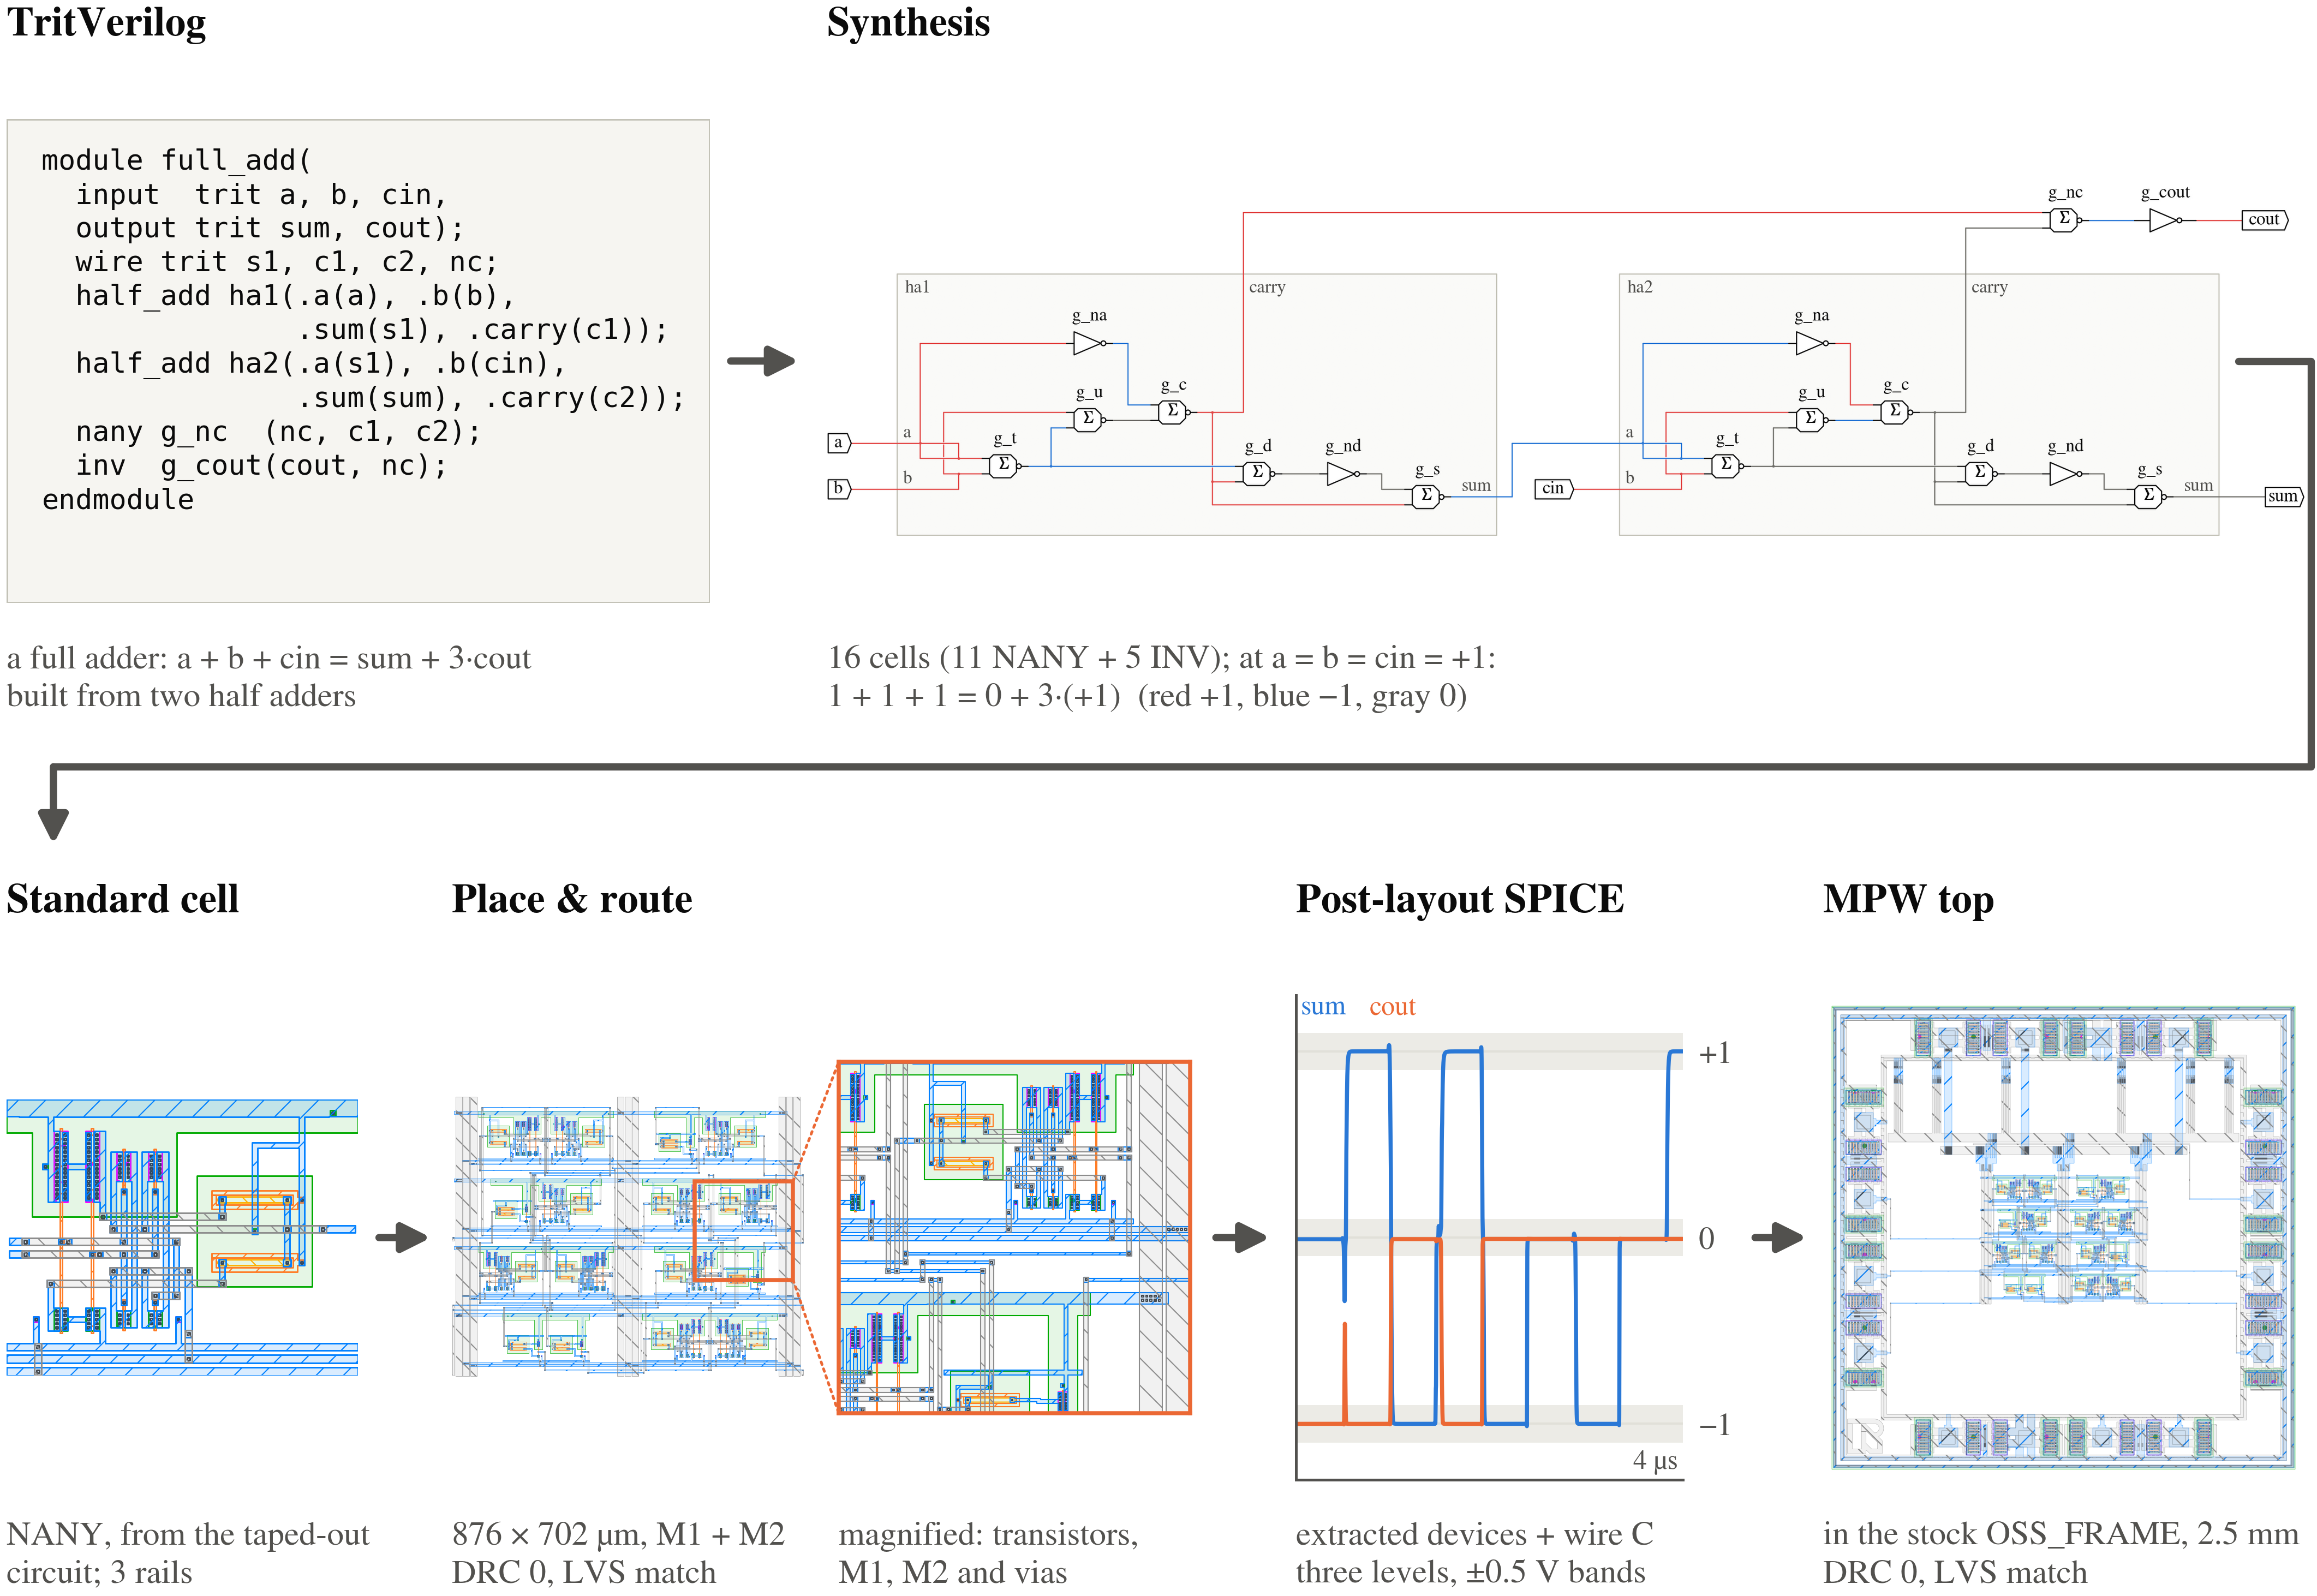

TritFlow works in **balanced ternary**. Each digit, or trit, takes one of three values, −1, 0 or +1, and the digit weights are powers of 3 (1, 3, 9, …). In the circuit, these values are −5 V, 0 V and +5 V. Balanced ternary has a long history: [Setun](https://doi.org/10.1007/978-3-642-22816-2_10), an early ternary computer built at Moscow State University in 1958, used it. It has recently drawn renewed attention through the large language model [BitNet b1.58](https://doi.org/10.48550/arXiv.2402.17764), whose weights are restricted to −1, 0 and +1. In its linear layers, multiplying an 8-bit input by such a weight yields the input, its negation or zero, so the matrix product (GEMM) needs only additions and subtractions, with no multipliers. Hardware that computes on ternary voltages directly, with no binary encoding in between, could therefore be highly efficient.

Today, however, ternary arithmetic runs on conventional binary logic, with each ternary value encoded in bits. Many ternary devices have been studied, including CNTFETs ([Lin et al., 2011](https://doi.org/10.1109/TNANO.2009.2036845)), memristors ([Wang et al., 2021](https://doi.org/10.1109/TCSI.2020.3027693)) and new CMOS structures ([Jeong et al., 2019](https://doi.org/10.1038/s41928-019-0272-8)). The design tools, though, have either stopped at [generating gate networks](https://doi.org/10.1109/ACCESS.2025.3597293) or encoded each ternary signal on several binary wires and run it through binary EDA ([MRCS](https://github.com/aiunderstand/MixedRadixCircuitSynthesis/tree/0865cee1f49fe9a803b4910b570f4e96e514c61b), [Takahe](https://github.com/Zaneham/takahe/blob/e7123ea60269922acb283d576678a3aabe51f4f4/designs/setun70_physical.sv), [Ankhdjet](https://doi.org/10.48550/arXiv.2608.26206)). To our knowledge, no physical design flow has taken HDL to GDS fully automatically on a manufacturable open-source PDK from a commercial fab, using CMOS cells that handle three physical voltage levels directly.

This notebook demonstrates such a flow on [OpenSUSI TR-1um](https://github.com/OpenSUSI/TR-1um/tree/5d963db9d44e192d37a0489c208bfccf2e2f690c) (Tokai Rika), the first open-source PDK released by a commercial semiconductor fab in Japan. TritFlow's standard cells reuse the circuit topologies and device sizes of [ternary logic circuits the author designed and taped out](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic/tree/8a60b97868cad008ff21fefca5da13dcd06063f8) in 2026 on OpenSUSI-TR10, the first OpenSUSI-MPW shuttle. A single pipeline takes a design written in TritVerilog, a dedicated ternary HDL, through logic synthesis, place and route, DRC/LVS and post-layout SPICE simulation.

The OpenSUSI-TR10 chips are due in January 2027. If this submission is selected, the author will present measurements of the ternary cells, together with a TritFlow demonstration, at ISSCC in February. A ternary circuit designed with TritFlow will then be fabricated on the next OpenSUSI shuttle. By closing the full loop of design, fabrication, measurement and conference presentation, this work aims to show that TR-1um, Japan's first commercial open-source PDK, has the potential to deliver the values that IEEE SSCS Code-a-Chip promotes, and to push forward Japan's open semiconductor ecosystem and the democratization of chip design.

**Reproducibility.** TritFlow is built so that the researchers, engineers and students who come after can understand how it works in detail, then rebuild and verify it themselves. The cell circuits, synthesis algorithms and place-and-route methods are kept simple enough to follow by reading the code. At the same time, the flow produces manufacturable GDS that passes the PDK's official DRC/LVS decks and is checked by post-layout simulation. Each notebook cell explains why its stage behaves as it does, with the physical and theoretical background, and readers can change parameters and see the effect immediately. Because the cells keep the circuits and device sizes of the taped-out design, simulation results can be compared directly with future measurements.

**Reusability.** Building on what they learn here, readers can extend TritFlow into their own research and designs. Editing a TritVerilog description is enough to regenerate a new, verified ternary core layout through the same automated flow. Later chapters go as far as a full-chip layout, generated automatically, that combines the four-term dot-product circuit with the MPW shuttle's stock frame and I/O pads. Because every algorithm lives in a clear Python module, new ternary gates can be added and the synthesis and place-and-route algorithms extended freely. The cell library, the EDA pipeline and this notebook are all open source (Apache-2.0) and can serve as a starting point for ternary logic research.

**Educational value.** This path from understanding to extension also makes TritFlow an excellent teaching resource for the next generation of students and engineers. Every step runs interactively on Google Colab, and rich visualizations (schematics, layouts, waveforms) and detailed numbers show how the netlist, layout and voltage waveforms change at each stage. Readers who know basic binary CMOS and introductory Verilog can follow, hands-on, the whole path from one line of HDL to GDS ready for fabrication. They do not stop at simulation: they finish with manufacturable GDS, in a design flow tied directly to measurement.

**License: Apache-2.0.**

In [2]:
#@title Setup { display-mode: "form" }

import os, sys, json, time, subprocess, importlib.util, re
from pathlib import Path
SOURCE_URL = "https://github.com/PenguinEino/tritflow.git"
SOURCE_REF = os.environ.get("TRITFLOW_REF", "e533a3cfbd39b07243faaa417b9ceb359da0c1f0")
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False

def git(*args, progress=None):
    """Run git; with ``progress``, show git's own counter on one redrawn line."""
    if progress is None:
        return subprocess.check_output(["git", "-C", str(ROOT), *args], text=True).strip()
    from IPython.display import display, HTML
    style = "font:13px/1.6 ui-monospace,Menlo,Consolas,monospace;white-space:pre"
    line = display(HTML(f'<div style="{style}">⠿ {progress}</div>'), display_id=True)
    process, text, started = subprocess.Popen(["git", *args], stderr=subprocess.PIPE, text=True), "", time.monotonic()
    for chunk in iter(lambda: process.stderr.read(64), ""):
        text += chunk
        parts = [p.strip() for p in re.split(r"[\r\n]", text)[:-1] if p.strip()]
        if parts:
            line.update(HTML(f'<div style="{style}">⠿ <b>{progress}</b>  <span style="color:#8a8f98">{parts[-1][:80]}</span></div>'))
    if process.wait():
        raise RuntimeError(f"git {' '.join(args[:2])} failed:\n{text[-2000:]}")
    line.update(HTML(f'<div style="{style}"><span style="color:#1a9c4a">✓</span> <b>{progress}</b>  '
                     f'<span style="color:#8a8f98">{time.monotonic()-started:.1f}s</span></div>'))

if IN_COLAB:
    ROOT = Path("/content/tritflow")
    if not re.fullmatch(r"[0-9a-f]{40}", SOURCE_REF):
        raise ValueError("TRITFLOW_REF must be a full 40-character commit")
    if not ROOT.exists():
        git("clone", "--progress", "--no-checkout", "--depth", "1", "--filter=blob:none",
            SOURCE_URL, str(ROOT), progress="Fetch source from GitHub")
        git("-C", str(ROOT), "fetch", "--progress", "--depth", "1", "origin", SOURCE_REF,
            progress=f"Commit {SOURCE_REF[:7]} · fetch")
        git("-C", str(ROOT), "switch", "--detach", SOURCE_REF, progress="Check out files")
    if git("rev-parse", "HEAD") != SOURCE_REF or git("status", "--porcelain", "--untracked-files=no"):
        # A runtime left by another version of this notebook: move it to the pinned commit and
        # drop the modules the kernel already imported from the old checkout.
        git("-C", str(ROOT), "fetch", "--progress", "--depth", "1", "origin", SOURCE_REF,
            progress=f"Commit {SOURCE_REF[:7]} · switch")
        git("reset", "--hard", SOURCE_REF)
        for name, module in list(sys.modules.items()):
            if str(getattr(module, "__file__", "") or "").startswith(str(ROOT)):
                del sys.modules[name]
else:
    candidates = [Path(os.environ.get("TRITFLOW_ROOT", ".")), Path.cwd(), Path.cwd().parent]
    ROOT = next((p.resolve() for p in candidates if (p/"tritflow").is_dir() and (p/"notebook").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("run from the TritFlow checkout or set TRITFLOW_ROOT")
sys.path[:0] = [str(ROOT), str(ROOT/"notebook")]
from live import step, run_stages, set_language as set_notebook_language
set_notebook_language("en")
from runtime_support import SETUP_SCHEMA, setup_identity, check_runtime, print_tool_versions
runtime = ROOT/"notebook/runtime.json"
if IN_COLAB and (not runtime.is_file()
                 or json.loads(runtime.read_text()).get("TRITFLOW_SETUP_SHA256") != setup_identity(ROOT)):
    os.environ["TRITFLOW_NOTEBOOK_LANGUAGE"] = "en"
    run_stages(["bash", str(ROOT/"notebook/colab_setup.sh"), "--source", str(ROOT)])
if runtime.is_file():
    os.environ.update(json.loads(runtime.read_text()))
    sys.path.insert(0, os.environ["TRITFLOW_PYTHON_TARGET"])
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")
with step("Check tools") as s:
    check_runtime()
    tools = print_tool_versions()
    s.done(" · ".join(re.search(r"(KLayout [\d.]+|ngspice-\d+)", v)[1] for v in tools.values()))
BUILD = Path(os.environ.get("TRITFLOW_NOTEBOOK_BUILD", "/content/build" if IN_COLAB else ROOT/"build/notebook")).resolve()

from live import need, provides, install_error_view, LayoutView
from views import pick_input, stimulus, bus_picker, cell_counts, schematic_view, scope_figure, timing_table, wire_table, delay_table, transient_conditions, dc_conditions, note
from IPython.display import HTML, display
import plotly.io as pio
pio.renderers.default = "colab"
from inverter_views import inverter
from pnr_views import replay
from cell_views import closure_view, cell_tables, cell_row
from tritflow import CELLS_DIR
from tritflow.sim.sizing import sweep_dimensions, load_grid
from tritflow import flow
from tritflow.viz.layout import gds_viewer
from tritflow.schematic import set_language
set_language("en")
install_error_view()
for name, cell in {"source": "1-1 HDL", "net": "1-2 Logic synthesis", "lay": "1-3 Place and route",
                   "lvs": "1-4 DRC and LVS", "post": "1-5 Post-layout simulation",
                   "dot4": "3-8 Logic synthesis", "dot4_layout": "4-1 Place and route",
                   "dot4_lvs": "5-1 DRC and LVS", "dot4_extracted": "5-2 Extraction and wire capacitance", "dot4_post": "5-3 Post-layout simulation",
                   "dot_scaling": "6-1 Dot-product size and area",
                   "reuse_source": "6-4 Edit HDL"}.items():
    provides(name, cell)


Python: numpy 2.4.3, scipy 1.17.1, matplotlib 3.10.8, plotly 7.1.0


KLayout: KLayout 0.30.9 (/home/ishi-kai/bin/klayout/klayout)
ngspice: ngspice-42 : Circuit level simulation program (/home/ishi-kai/.local/opt/tritflow-ubuntu-24.04/bin/ngspice)


## 1. First Circuit: `a & ~a` to GDS

This chapter runs `a & ~a`, a small circuit that already behaves in a distinctly ternary way, through the whole TritFlow flow in one pass: HDL description, logic synthesis, place and route, DRC/LVS and post-layout SPICE simulation. Later chapters explain each stage in turn.

In binary logic, ANDing an input a with its inverse, `a & ~a`, always gives false (0), so the circuit collapses into a constant tied to ground. Balanced ternary logic behaves differently.

As the table below shows, balanced-ternary AND takes the smaller of its two inputs (min), and negation (NOT, `~`) flips the sign (+1 ↔ −1, 0 ↔ 0). When a is +1 or −1, the output is the minimum, −1. When a = 0 (0 V), ~a is also 0, so 0 & 0 gives **0 (0 V)**. `a & ~a` is therefore not a constant but a genuine ternary circuit, with its own middle-level output for a = 0.

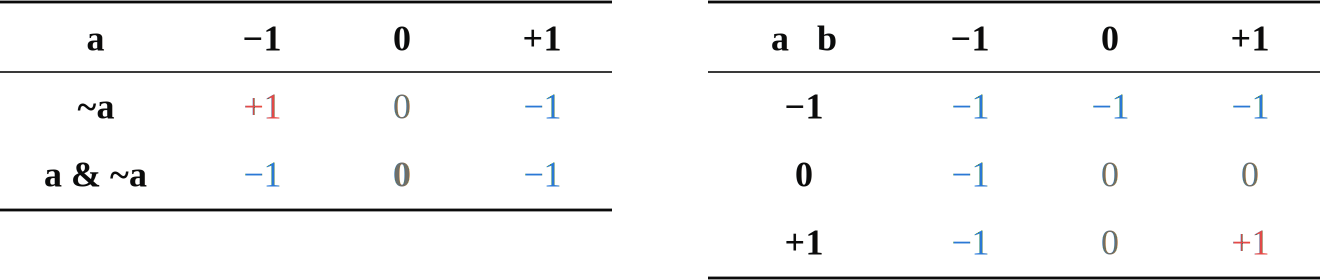

### 1.1 HDL Description (TritVerilog)

First, the circuit is written in TritVerilog, TritFlow's dedicated HDL. Ternary signals are declared with the type `trit`, and an `assign` statement describes the AND `&` and the negation `~`.

In [3]:
# 1-1 HDL
source = """
module first(input trit a, output trit y);
  assign y = a & ~a;
endmodule
"""

### 1.2 Logic Synthesis

The synthesizer parses the HDL and converts it into a netlist of ternary standard cells. It maps the ternary expression directly onto ternary cells, here INV for negation and NAND for negated AND. At the same time, it evaluates every input pattern (here the three values a = −1, 0, +1) and checks automatically that the netlist matches the original HDL exactly.

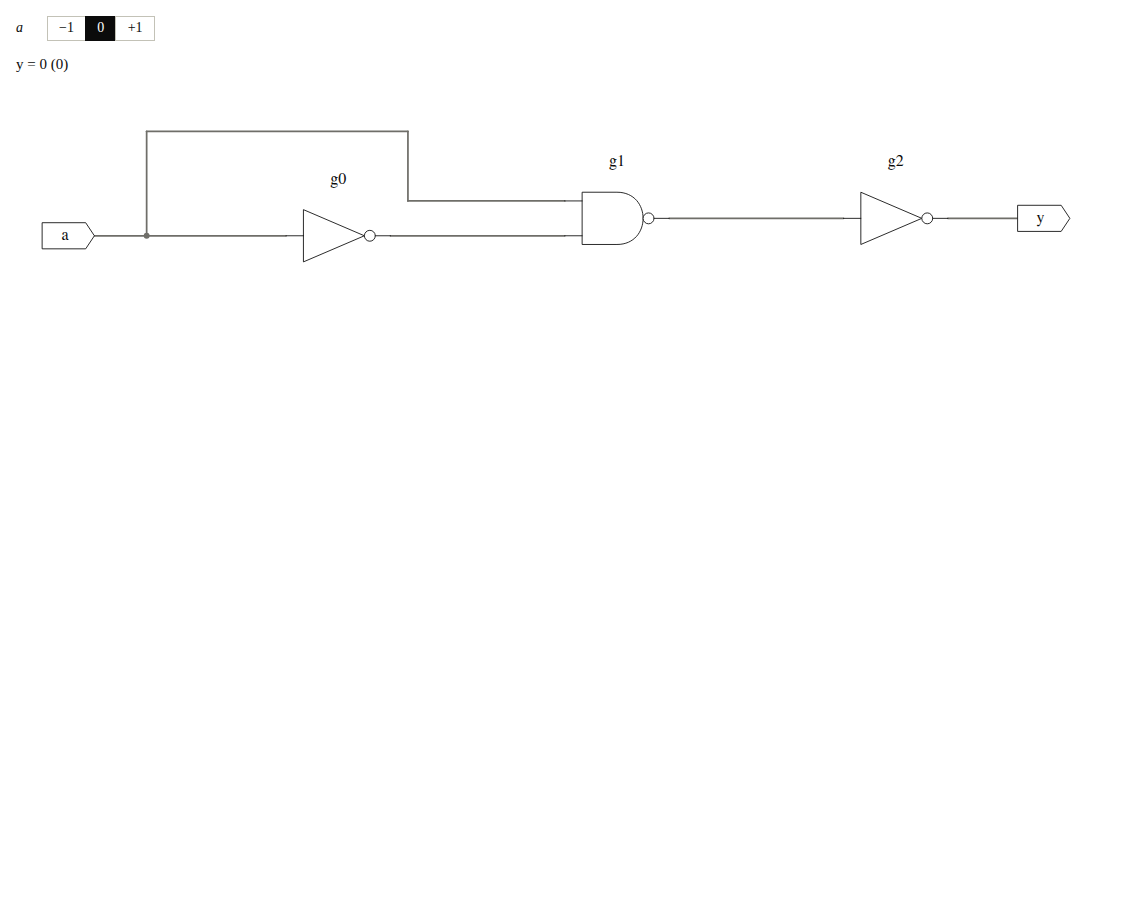

In [4]:
# 1-2 Logic synthesis
need("source", why="The HDL to synthesize is defined in 1-1.")
with step("Parse HDL and synthesize") as s:
    net = flow.loads(source).synthesize()
    s.done(" · ".join(f"{cell}×{n}" for cell, n in net.report()["cells"].items())
           + (" · equivalent for all inputs" if net.equivalence["passed"] else " · not equivalent"))
bus_picker(net)

### 1.3 Place and Route

The placer arranges the cells of the synthesized netlist according to the TR-1um design rules, and the router connects them on two metal layers (M1/M2). The cells sit side by side so that the three power rails running through them (from the top, VDD = +5 V, VMID = 0 V, VSS = −5 V) abut without gaps, and the signal wires stay short.

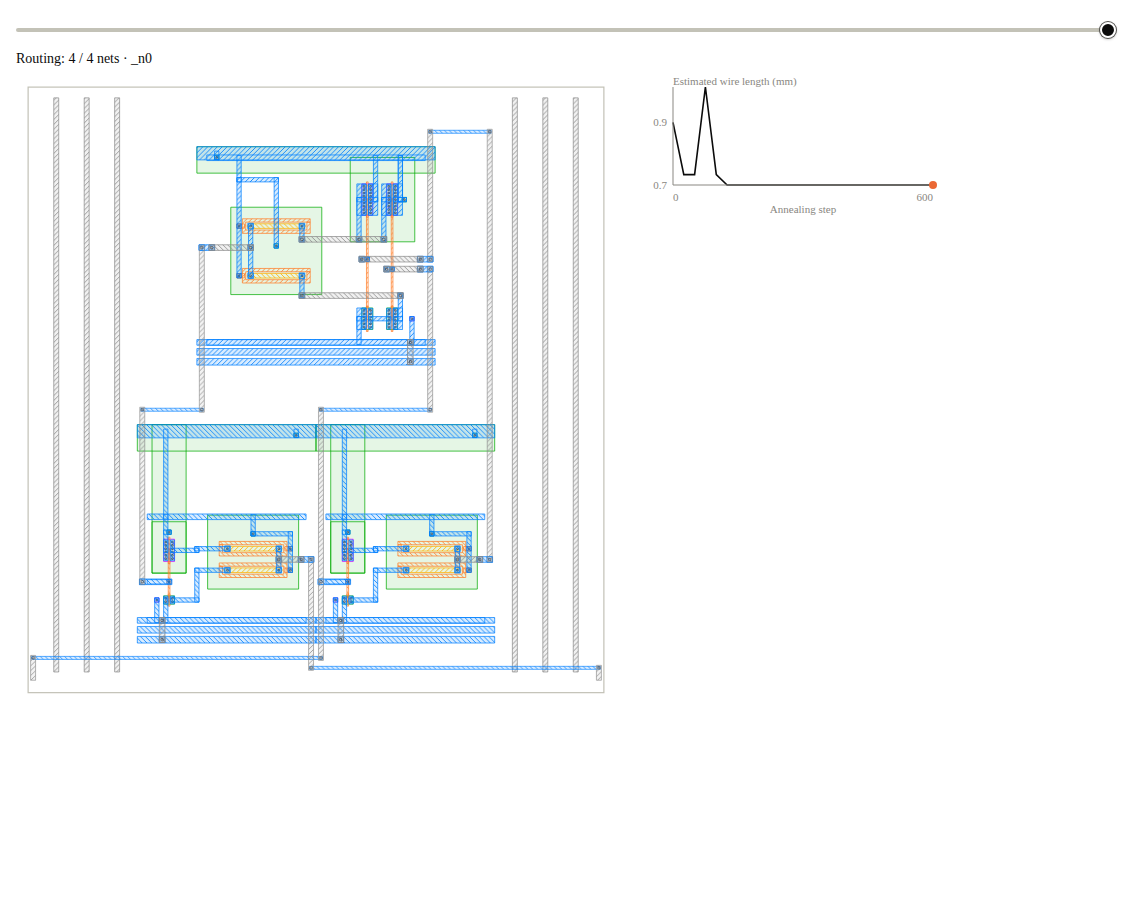

In [5]:
# 1-3 Place and route
need("net", why="The netlist net is synthesized in 1-2.")
with step("Place and route", view=LayoutView()) as s:
    lay = net.place_and_route(output_dir=BUILD/net.top, seed=0)
    width, height = lay.stats["die_size_um"]
    s.done(f"{lay.stats['instance_count']} cells · {width:.0f} × {height:.0f} µm · Routed nets: {lay.stats['routed_nets']}",
           picture=replay(lay))

### 1.4 DRC and LVS

The PDK's official KLayout decks check whether the finished layout meets the fab's manufacturing rules. DRC (Design Rule Check) looks for design-rule violations, and LVS (Layout Versus Schematic) checks that the transistor connections extracted from the layout match the synthesized netlist. Both run automatically; check that both pass with zero errors.

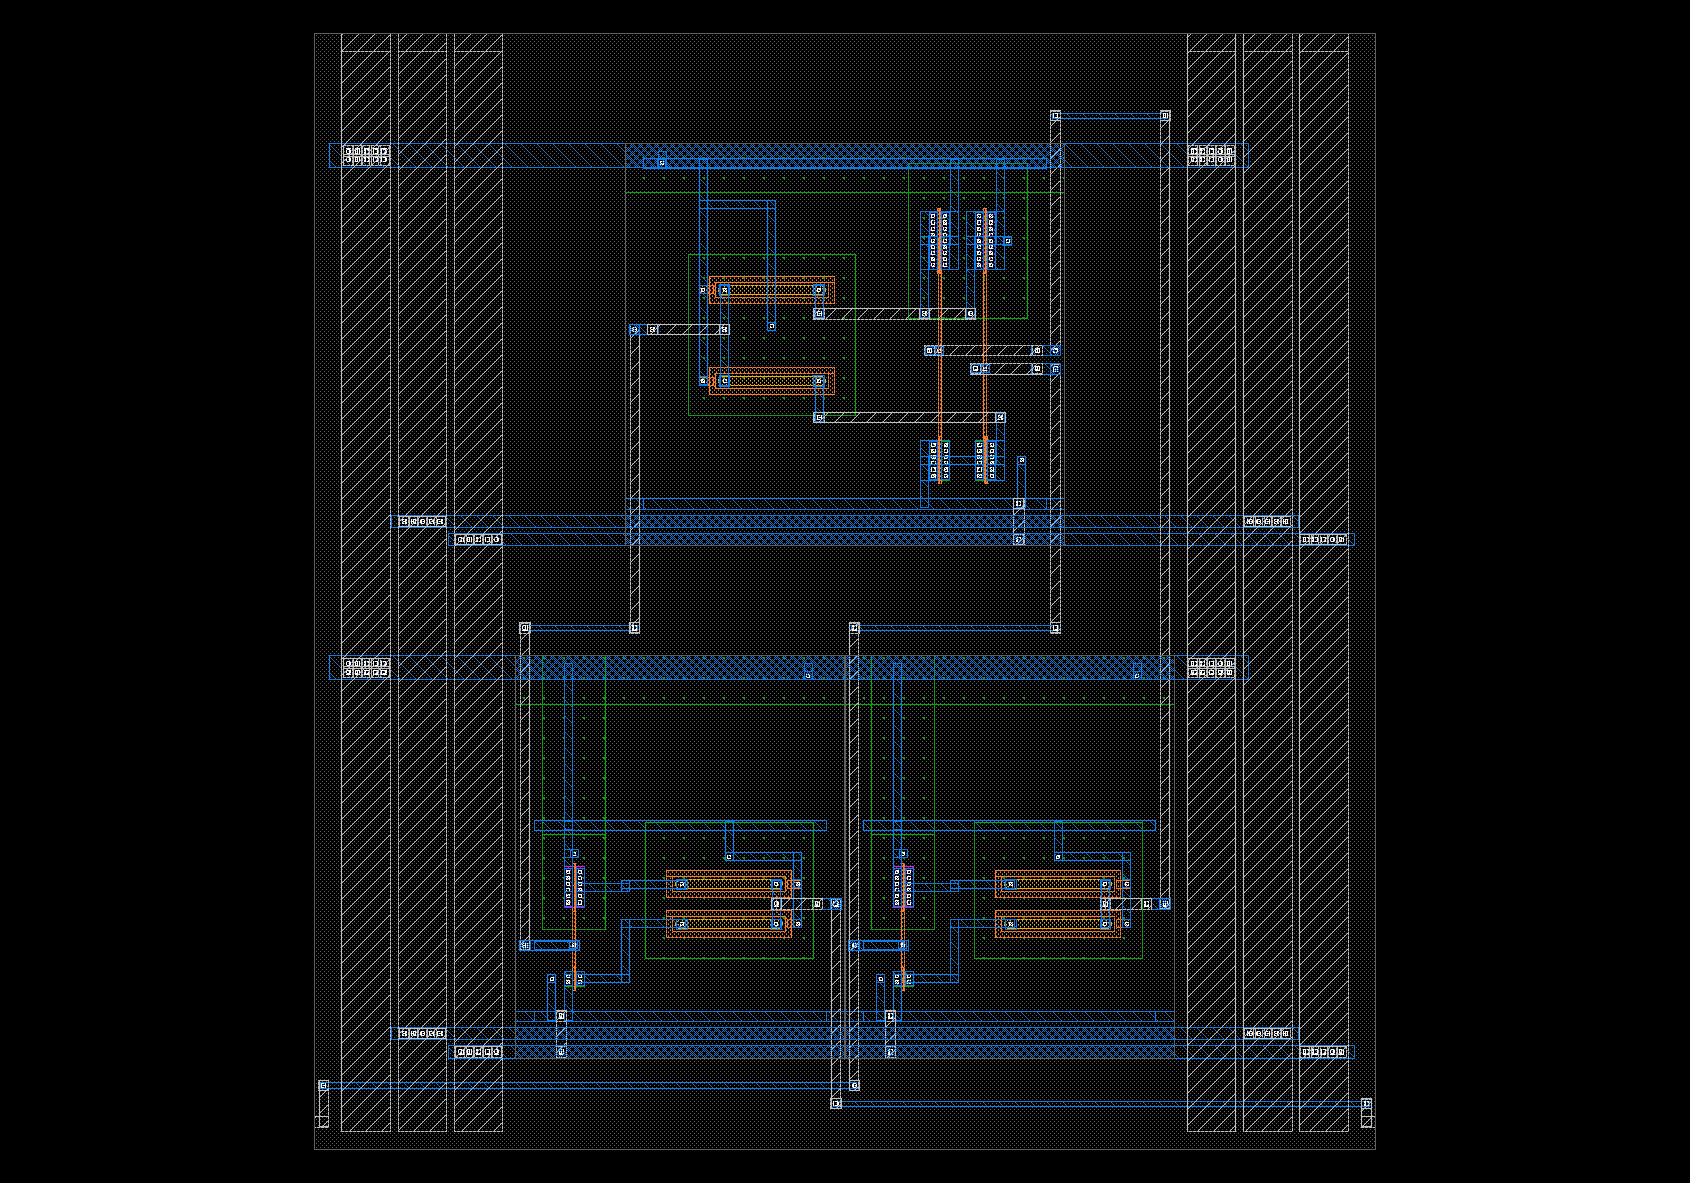

In [6]:
# 1-4 DRC and LVS
need("lay", why="DRC and LVS check the GDS generated in 1-3.")
with step("DRC") as s:
    drc = lay.drc()
    s.done(f"Violations: {drc['violations']}")
with step("LVS") as s:
    lvs = lay.lvs()
    s.done("Matched" if lvs["matched"] else "Mismatch")
gds_viewer(lay.gds_path)

### 1.5 Post-Layout Simulation

The flow estimates wire capacitance from the layout geometry, writes a SPICE netlist with the actual transistor dimensions and runs a transient analysis in ngspice. As input a steps through −5 V → 0 V → +5 V → 0 V → −5 V, the interactive waveforms show the output settling into the ±0.5 V acceptance band around its target level (−5 V, 0 V or +5 V), along with the voltage of each internal node.

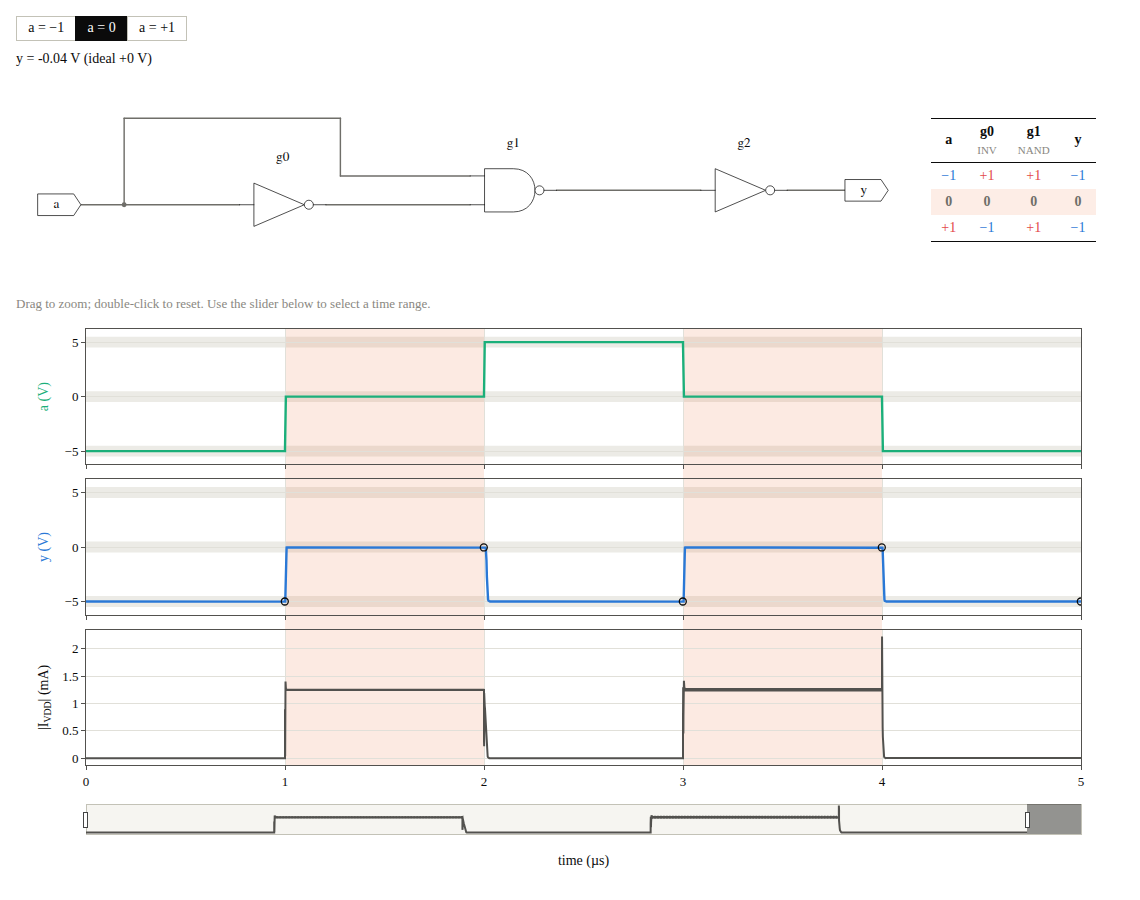

In [7]:
# 1-5 Post-layout simulation
need("lvs", why="Simulation uses the circuit extracted from the LVS-matched GDS in 1-4.")
with step("Extraction and wire capacitance") as s:
    extracted = lay.extract()
    signals = [n for n in extracted.capacitance["nets"] if n not in ("VDD", "VMID", "VSS")]
    s.done(f"Wire capacitance added to {len(signals)} signal nets")
with step("ngspice") as s:
    post = extracted.simulate(stimulus(net), load=100e-15, hold_s=1e-6, step_s=2e-9,
                              edge_s=1e-9, temperature_c=27)
    s.done("within the ±0.5 V band in every interval" if post["measurements"]["passed"] else "outside the band in some intervals")
pick_input(net, post)
transient_conditions(post, load_f=100e-15)

That completes one pass from ternary HDL to manufacturable GDS, with a functional check. The figure below summarizes the whole pipeline and the inputs and outputs of each stage.

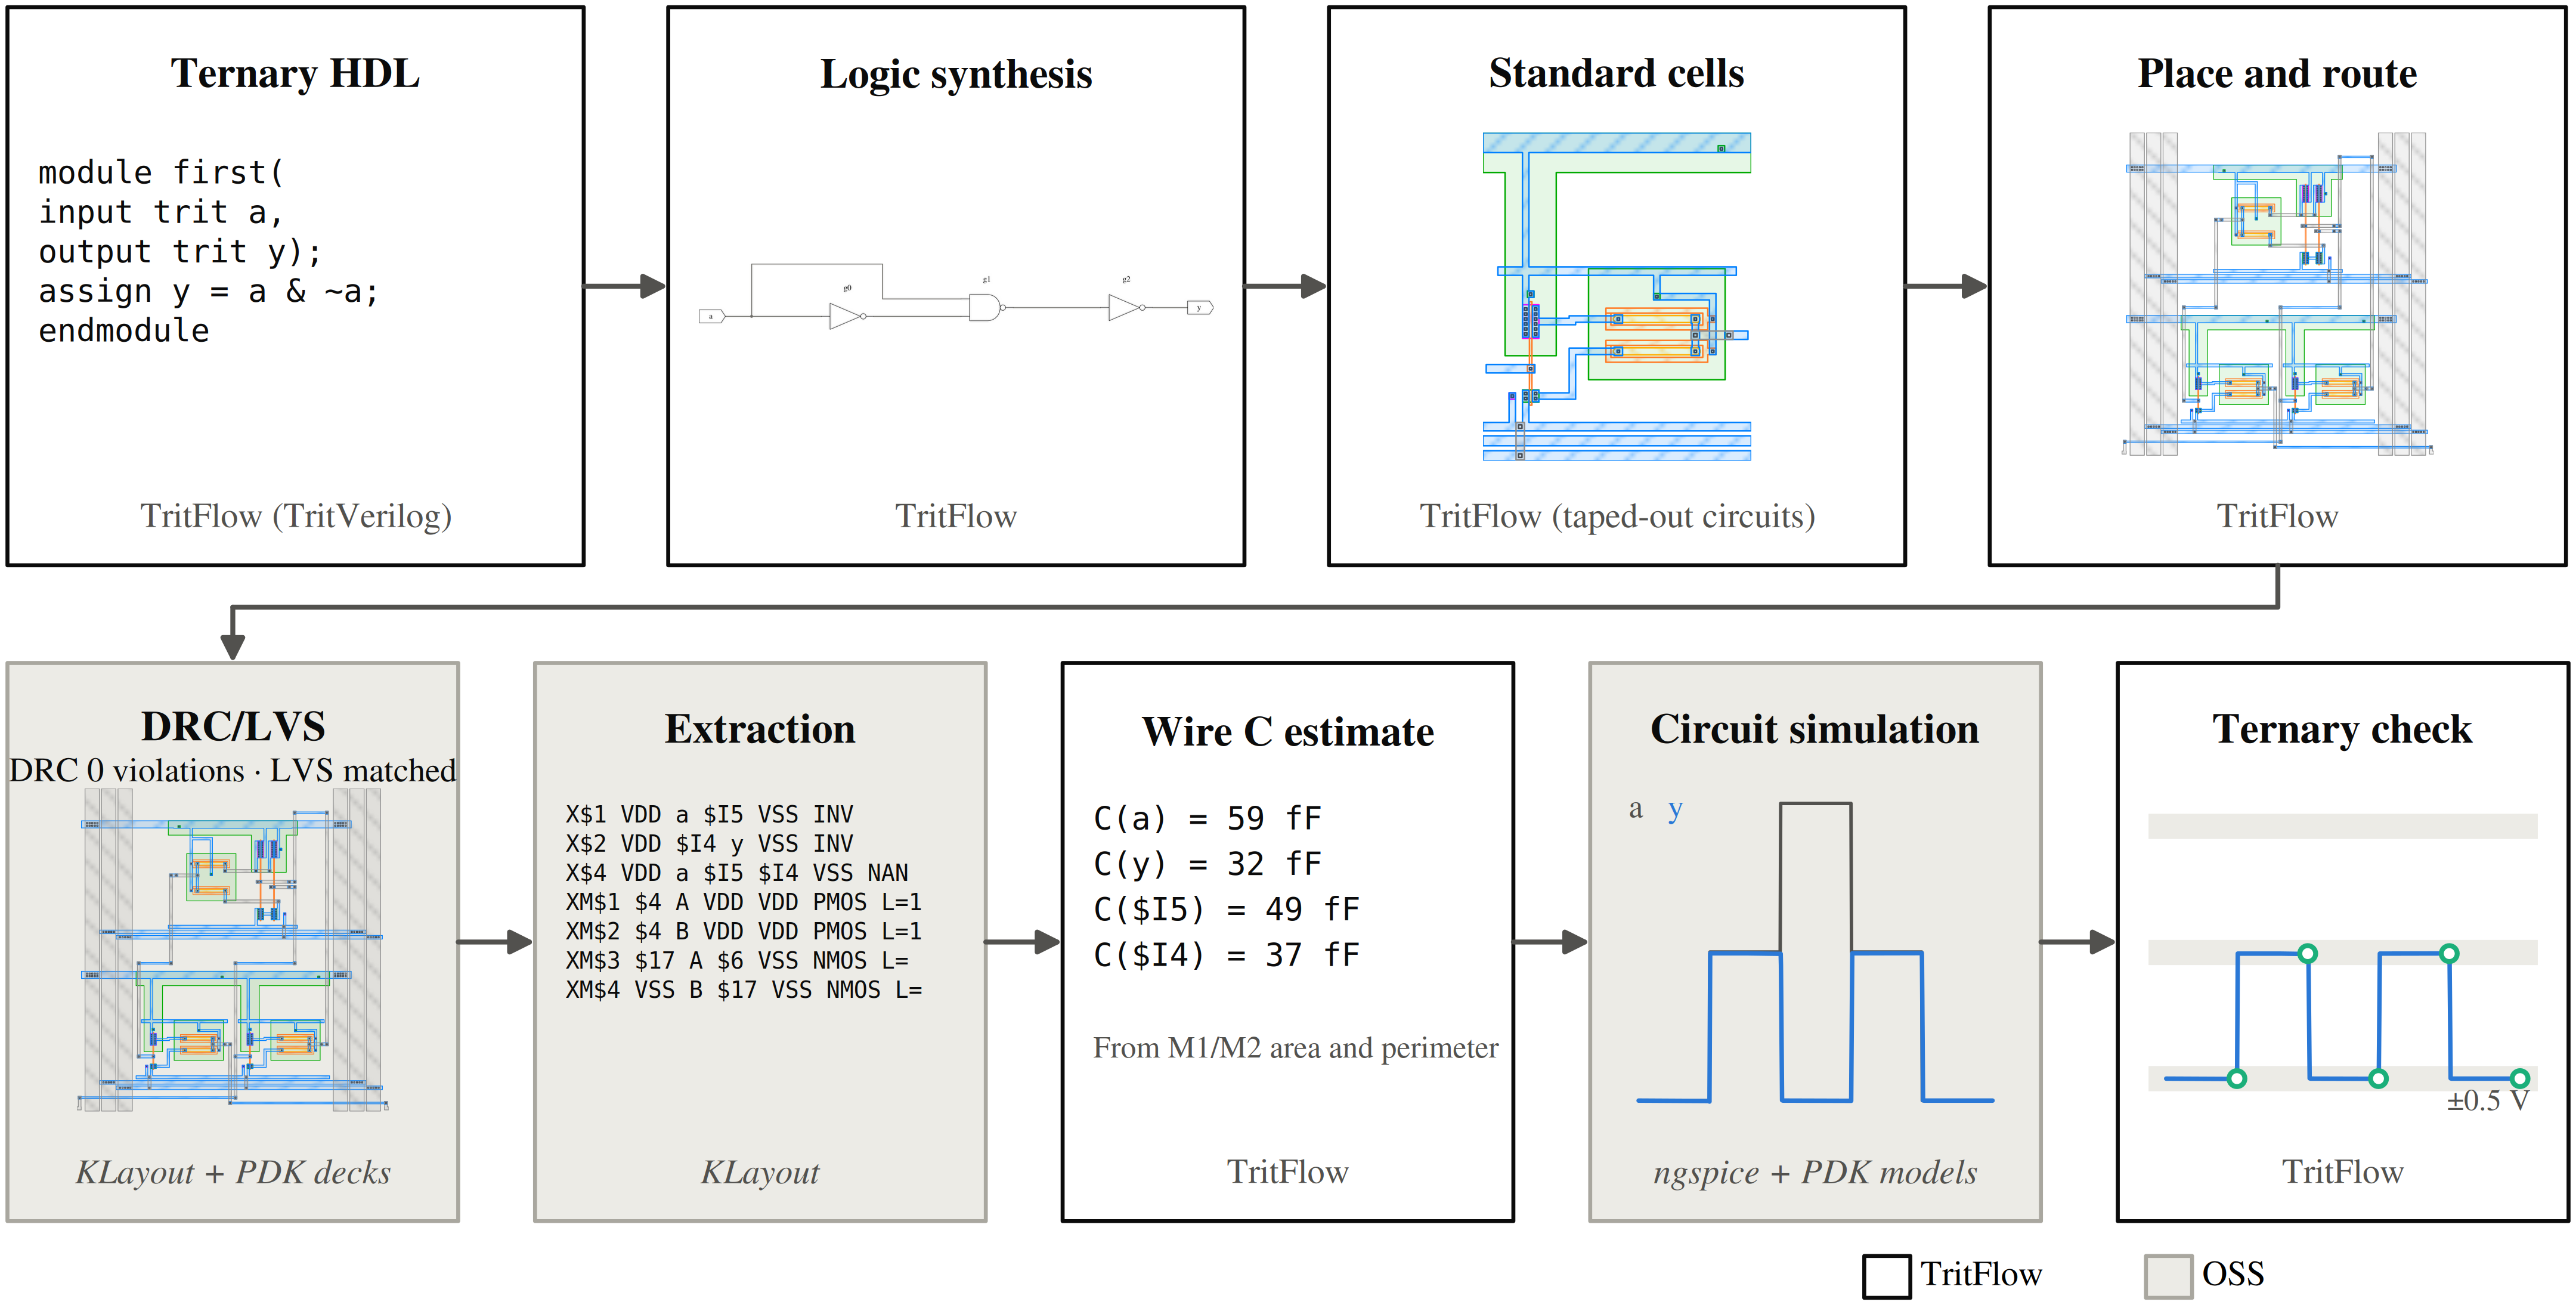

## 2. Cells

The circuit in chapter 1 used two standard-cell types, INV and NAND. This chapter describes the standard cells behind TritFlow. It starts with INV to show how CMOS produces three voltage levels, then establishes which cells can build any ternary logic, and finally shows how the taped-out circuits became standard cells for place and route.

### 2.1 INV: Generating Three Levels

What sets the ternary INV apart from a binary inverter is that, to output 0 V, it turns on both the upper and lower MOS transistors and forms the middle level with a voltage divider.

TritFlow's INV places a PMOS, two diffusion resistors (PDK device RR) and an NMOS in series between VDD and VSS. Output Y is taken between the two resistors.

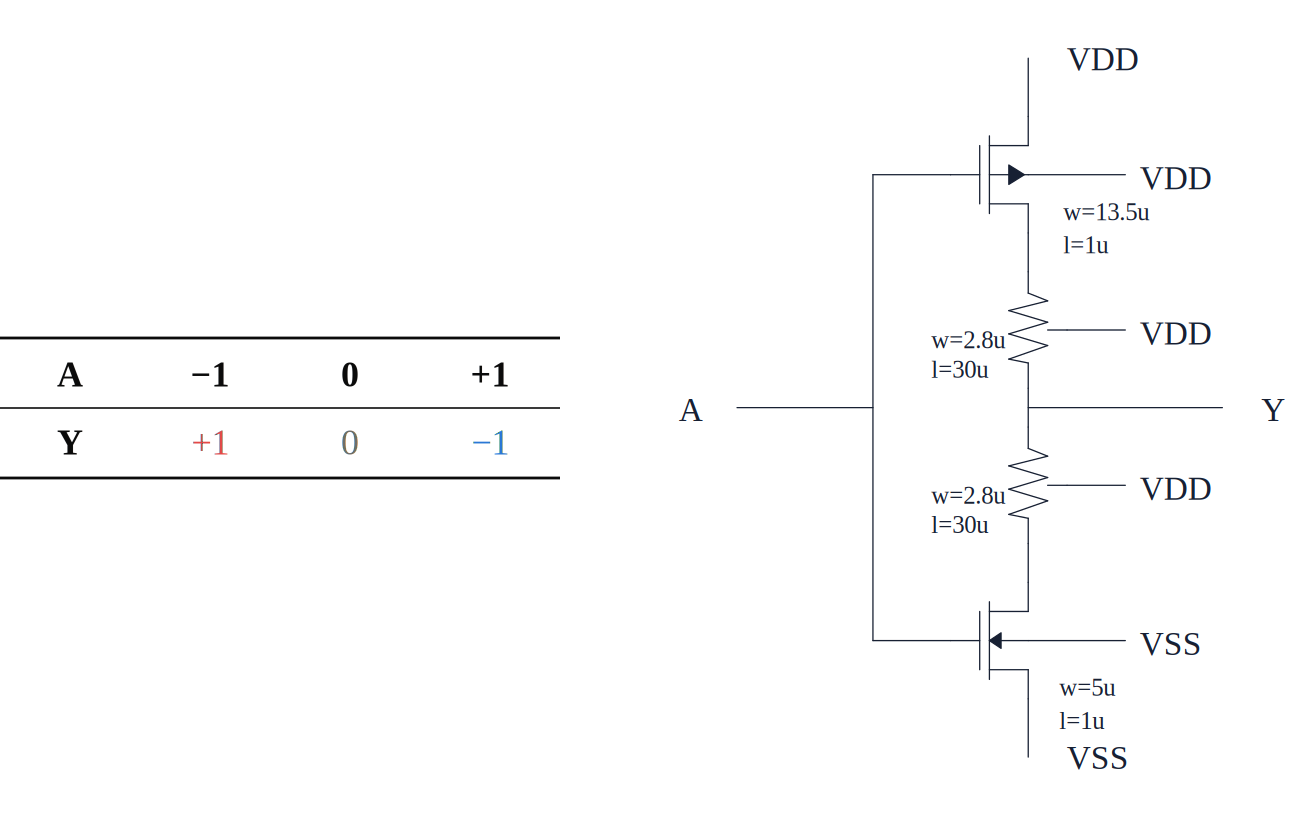

At an input of ±5 V, only one MOS transistor conducts, pulling Y to its rail. At an input of 0 V, both conduct, and the divider outputs 0 V. No rail supplies this 0 V; it comes solely from the balance of the upper and lower resistances, and static current flows the whole time.


#### SPICE Simulation

The figure shows a DC analysis with ngspice and the PDK models over 90 device sizings, including the taped-out one.

The taped-out sizing was chosen as a trade-off among middle-level accuracy, delay, area and static current. TritFlow's cells keep it unchanged so that they can be compared with measurements. The grid in the figure also contains sizings with both smaller error and smaller static current.

- **Target**: as the middle-level noise margin, an output within ±0.5 V for inputs from −1 to +1 V.
- **Gate length**: the minimum, 1 µm, for drive strength and area.
- **PMOS and NMOS widths**: at an input of 0 V, the output is 0 V when the upper on-resistance plus RR, r<sub>on,P</sub> + R<sub>RP</sub>, equals the lower r<sub>on,N</sub> + R<sub>RN</sub>. Holes are less mobile than electrons, so the PMOS is made wider than the NMOS to bring their on-resistances closer and reduce the output offset.
- **RR width**: the minimum, 2.8 µm.
- **RR length**: 30 µm, to keep the static current of the whole taped-out chip within the current limits of the power wires and vias. The MOS dimensions were left as they were before RR was lengthened, so an offset of a few tens of mV remains at an input of 0 V, well within the ±0.5 V acceptance band.

The adopted PMOS and NMOS widths are 13.5 µm and 5 µm. The PDK's zero-bias resistance equation gives 10.835 kΩ for each RR. Approximating each MOS as a linear resistor from its mobility, oxide thickness and threshold voltage gives r<sub>on,P</sub> = 0.492 kΩ and r<sub>on,N</sub> = 0.399 kΩ. Each RR is 22.0 times r<sub>on,P</sub> and 27.2 times r<sub>on,N</sub>, so the zero level is set by the ratio of two identically shaped resistors rather than by MOS variation. With R<sub>u</sub> = r<sub>on,P</sub> + R<sub>RP</sub> above Y and R<sub>d</sub> = r<sub>on,N</sub> + R<sub>RN</sub> below it, the divider gives

$$V_Y = V_{SS} + (V_{DD}-V_{SS})\frac{R_d}{R_u+R_d} \simeq -0.021\ \mathrm{V},\qquad I = \frac{V_{DD}-V_{SS}}{R_u+R_d} \simeq 0.443\ \mathrm{mA}$$

SPICE gives −0.040 V and 0.407 mA; the difference comes from the approximation ignoring the voltage and substrate-bias dependence of RR and the nonlinearity of the MOS transistors.

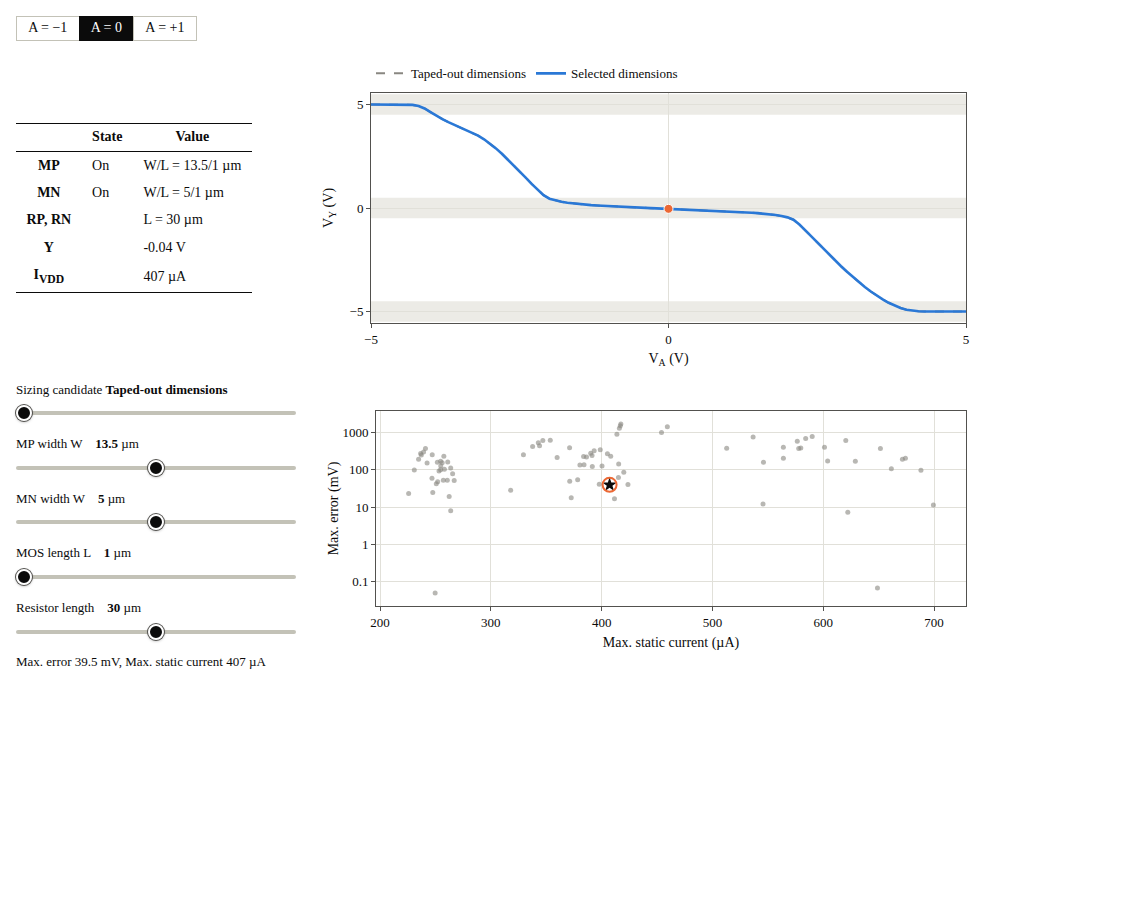

In [8]:
# 2-1 INV DC analysis and sizing
with step("INV DC analysis") as s:
    spice = sweep_dimensions("INV", [], workdir=BUILD/"inv")
    zero = next(r for r in spice["rows"][0]["dc"] if r["input_trits"] == [0])
    s.done(f"Input 0 V: Y = {zero['output_v']['Y']:+.3f} V · {abs(zero['rail_current_a']['VDD'])*1e3:.3f} mA")
with step("Check recorded sizing data") as s:
    grid = load_grid("INV")
    s.done(f"{len(grid['rows'])} candidates · schematic, models and analysis code match")
from predictions import divider, rail_power
from tritflow import PDK_ROOT
from style import figure_css, table_css
inv_hand = divider(grid["rows"][grid["adopted_index"]]["dimensions"], PDK_ROOT)
upper, lower = inv_hand["upper"], inv_hand["lower"]
resistances = [upper["rr_ohm"], upper["ron_ohm"], lower["ron_ohm"],
               upper["total_ohm"], lower["total_ohm"]]
comparison = [("V<sub>Y</sub> (V)", inv_hand["output_v"], zero["output_v"]["Y"], "+.3f"),
              ("I (mA)", inv_hand["current_a"]*1e3, abs(zero["rail_current_a"]["VDD"])*1e3, ".3f"),
              ("P (mW)", inv_hand["power_w"]*1e3,
               rail_power(zero, grid["conditions"]["supplies_v"])*1e3, ".3f")]
display(HTML('<style>'+figure_css('.inv-estimate')+table_css('.inv-estimate')+'</style>'
    + '<div class="inv-estimate"><table><tr>'
    + ''.join(f'<th>{label}<small>kΩ</small></th>' for label in
              ('R<sub>RR</sub>', 'r<sub>on,P</sub>', 'r<sub>on,N</sub>', 'R<sub>u</sub>', 'R<sub>d</sub>'))
    + '<th>R<sub>RR</sub>/r<sub>on,P</sub></th><th>R<sub>RR</sub>/r<sub>on,N</sub></th></tr><tr>'
    + ''.join(f'<td>{r/1e3:.3f}</td>' for r in resistances)
    + f'<td>{upper["rr_ohm"]/upper["ron_ohm"]:.1f}</td><td>{lower["rr_ohm"]/lower["ron_ohm"]:.1f}</td></tr></table>'
    + '<table style="margin-top:1em"><tr><th>Input 0 V</th><th>Resistive estimate</th><th>SPICE</th></tr>'
    + ''.join(f'<tr><td>{label}</td><td>{estimate:{fmt}}</td><td>{measured:{fmt}}</td></tr>'
              for label, estimate, measured, fmt in comparison)
    + '</table></div>'))
inverter(spice, grid)
dc_conditions()

### 2.2 Completeness: Which Cells Build Any Ternary Logic

Logic synthesis rewrites the logic written in HDL as a combination of the available cells. For this to work for any logic, the cell set must be **functionally complete**: wiring its cells together must be enough to build every logic function. In binary logic, NAND alone is complete.

In ternary logic, two cells are enough: NANY, below, and the constant cell TIEP.

- **NANY**: a two-input cell defined in TritFlow. It clips the sum of its inputs to the range −1 to +1, then negates it. NANY(a, b) = −sat(a + b)
- **sat**: the function that clips to the range −1 to +1. sat(x) = max(−1, min(+1, x))
- **TIEP, TIEZ, TIEN**: constant cells that output +1, 0 and −1, named after the binary tie cells (TIEHI, TIELO). Either TIEP or TIEN is enough for completeness.

The proof rests on Słupecki's criterion (1939): a set of ternary functions is complete if it satisfies both of the following conditions.

1. It can build every one-input (unary) function. Since the output can be chosen independently for each of the three values of a (−1, 0, +1), there are 3 × 3 × 3 = 27 unary functions, and all 27 must be generated.
2. It can build at least one essential two-input function: a function of a and b that depends on both (with either input fixed, changing the other can change the output) and takes all three output values, −1, 0 and +1.

NANY satisfies condition 2 by itself. Since NANY(a, 0) = −a, any change in a appears directly at the output, and the same holds for b by symmetry. Its output also takes all of −1, 0 and +1.

For condition 1, the code starts from just the input variable a and the constant +1, feeds the outputs of the functions found so far back into NANY inputs, and checks exhaustively that all 27 unary functions appear. The table below shows how the set of generated functions grows with NANY logic depth.

In [9]:
# 2-2 Unary functions from NANY and the +1 constant
from completeness import generations, surjective_and_depends_on_both, nany
found = generations(binary=(nany,), constants=(1,))
print(f"Unary functions constructed: {len(found)} / 27; maximum depth {max(found.values())} stages")
print("NANY depends on both inputs and takes all three output values (−1, 0, +1):", surjective_and_depends_on_both(nany))
closure_view(found)

Unary functions constructed: 27 / 27; maximum depth 5 stages
NANY depends on both inputs and takes all three output values (−1, 0, +1): True


Why does NANY need a constant cell? Since NANY(0, 0) = −sat(0 + 0) = 0, when every input is 0 (0 V), any network of NANY cells keeps outputting 0 and can never produce anything else. A single nonzero constant removes this limit. With +1 from TIEP, for example, NANY(+1, +1) = −1 and NANY(+1, −1) = 0 give the other constants, so one constant cell is enough.

### 2.3 Standard-Cell Library

The standard cells TritFlow provides are listed below. The four main logic gates, INV, NAND, NOR and NANY, are exactly the circuits taped out on OpenSUSI-TR10. NAND and NOR are not needed for completeness, but they reduce the logic depth of the netlist and so improve area and delay. The library also has a buffer, BUF (two INV stages in series), for driving high-fanout signals, and the constant cells TIEP, TIEZ and TIEN.

In the schematic symbols, the open circle at an output means negation (NOT), and NAND and NOR keep their familiar binary shapes. NANY has its own symbol, which combines a summing block (Σ) with saturation and negation.

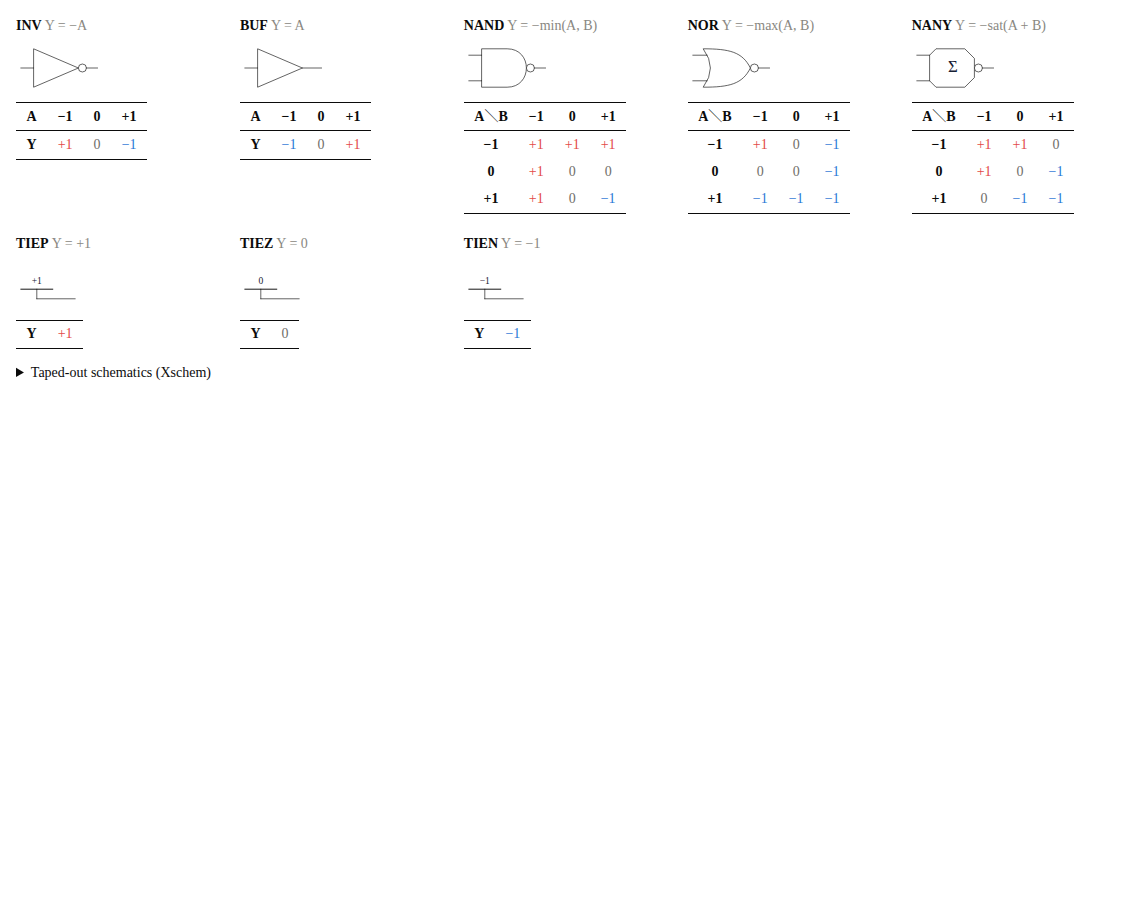

In [10]:
# 2-3 Cell truth tables
cell_tables(CELLS_DIR/"out", ROOT/"notebook/assets/schematics")

### 2.4 Standard-Cell Layout

Automatic place and route (P&R) only works if every cell follows strict geometric rules. All cells in TritFlow's library share a row height (cell height) of **132 µm** and a placement and routing grid pitch of **6 µm**.

Three first-metal (M1) power rails run horizontally through each cell, from the top **VDD (+5 V, 8 µm wide)**, **VMID (0 V, 4 µm wide)** and **VSS (−5 V, 4 µm wide)**. Placing cells side by side without gaps is enough to connect the power rails and the N-well continuously. The input and output pins are M1 landings on the routing grid, so second-metal (M2) wires crossing over them can reach them easily through vias (V1). Cells can be placed in their normal orientation (R0) or mirrored left to right (MY).

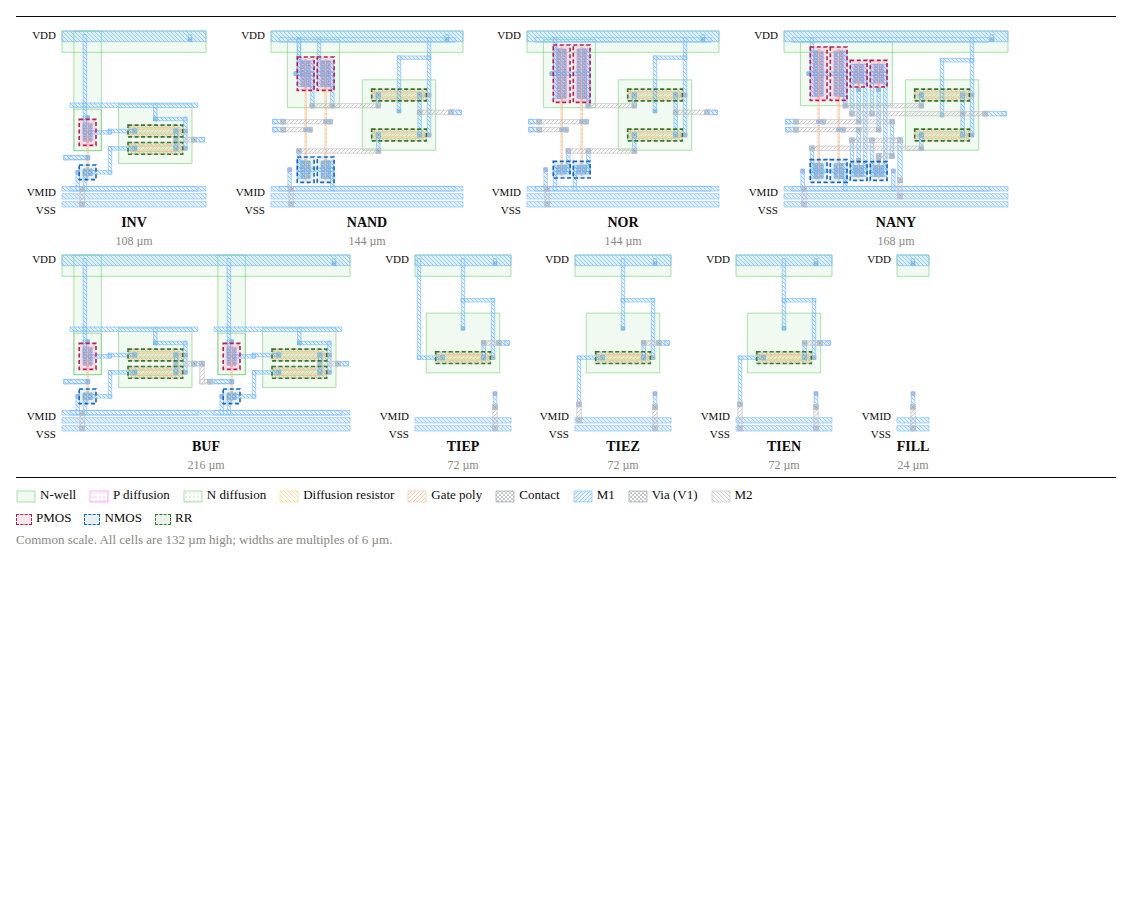

In [11]:
# 2-4 Standard cells
import json
cell_row(json.loads((CELLS_DIR/"out/library.json").read_text()), CELLS_DIR/"out")

## 3. HDL and Logic Synthesis

Chapter 2 showed that TritFlow's cell library is functionally complete, so it can implement any ternary logic. This chapter covers TritVerilog, the dedicated HDL for ternary circuits, and the logic synthesis engine that turns a TritVerilog description into a netlist of standard cells. TritVerilog extends the syntax of industry-standard Verilog naturally to ternary values, so ternary digital circuits can be written with a familiar, intuitive grammar.

### 3.1 Values and Numbers

A signal value, or trit, is −1, 0 or +1, corresponding to −5 V, 0 V or +5 V. Used as a condition, these values mean false, unknown and true. Unknown is the valid trit 0 at a physical 0 V; it is not Verilog's undefined value X or high impedance Z.

A vector of trits (for example `trit [1:0] a;`) represents an integer in **balanced ternary**. Counting from the least significant digit, digit i has weight 3<sup>i</sup>. In numeric literals, −1 is written `T` (or lowercase `t`); for example, `2'tT1` is −1·3 + 1 = −2. In general, n trits represent exactly the 3<sup>n</sup> integers from −(3<sup>n</sup> − 1)/2 to +(3<sup>n</sup> − 1)/2; two trits give the nine integers from −4 to +4.

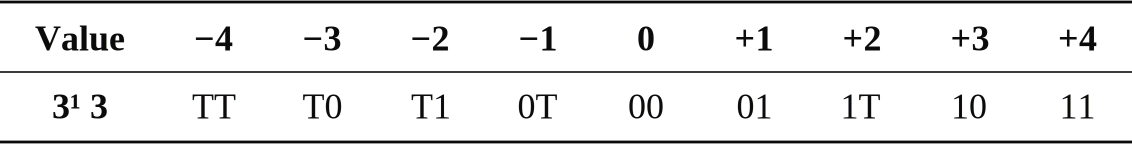

Balanced ternary has advantages that binary representations such as two's complement lack.

- **No sign bit**: because the digits are symmetric around 0, positive numbers, zero and negative numbers share one format, with no dedicated sign bit.
- **Negation is immediate**: negating a number (−a) only flips the sign of every digit (T ↔ 1). Unlike two's complement, which inverts every bit and then adds 1 to the least significant bit, it involves no carry propagation.
- **Truncation rounds to the nearest value**: because every digit is −1, 0 or +1, dropping lower digits leaves an error smaller than half the weight of the lowest digit kept, symmetric about zero. TritVerilog's `a >> 1` (divide by 3 and round to the nearest integer) gets this rounding simply by dropping the least significant digit.

### 3.2 Syntax

The table below summarizes TritVerilog's main operators and constructs, and the cell netlists that logic synthesis maps them to.

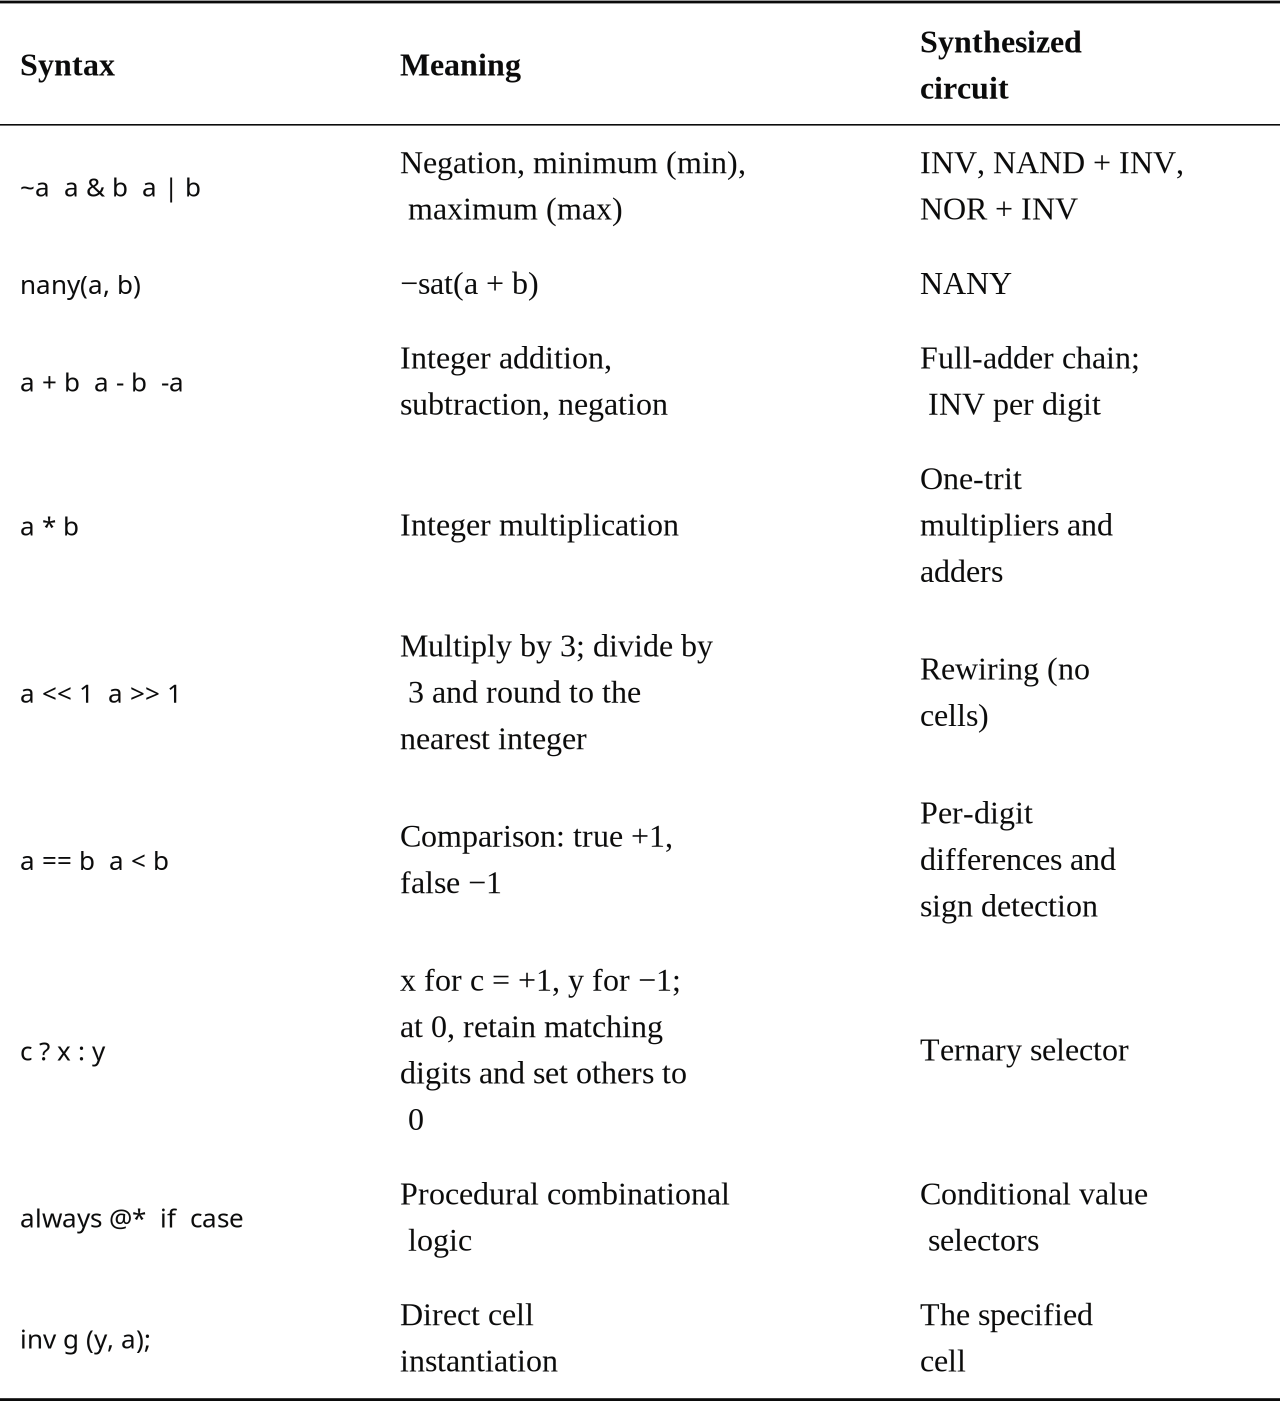

Width rules follow Verilog: operations take the width of the assignment target. Operands narrower than the target are padded with 0 in the upper digits, and upper digits that do not fit in the target are discarded.

### 3.3 Synthesis Stages

TritFlow's logic synthesis engine is a deterministic compiler written in Python. It produces a netlist in five stages.

1. **Parsing and elaboration**: the TritVerilog source is parsed into an abstract syntax tree (AST), and the module hierarchy, parameters (`parameter`) and generate statements (`generate`) are elaborated into a logic intermediate representation. Procedural assignments inside `always @*` blocks are normalized to static single assignment (SSA) form, which tracks each signal's value at every assignment, and conditional branches such as `if` and `case` become selectors.
2. **Technology mapping**: each operator is replaced with a dedicated cell structure. Addition and subtraction become carry chains of full and half adders with the same structure as the taped-out circuits; comparisons become circuits that saturate the per-digit differences and decide the sign from the most significant digit; equality (`==`) and `case` labels become per-digit equality detectors. Selectors are described in section 3.5.
3. **Logic optimization**: constants are folded, common subexpressions shared and unused gates removed. Expressions are then simplified with the following identities, which still hold in ternary logic even though it is not a Boolean algebra.
   - Double negation: −(−x) = x
   - Idempotence: min(x, x) = x, max(x, x) = x
   - min and max with constants: min(x, +1) = x, min(x, −1) = −1, max(x, +1) = +1, max(x, −1) = x
   - NANY with a 0 input: NANY(x, 0) = −x
   - De Morgan's laws: min(−a, −b) = −max(a, b), max(−a, −b) = −min(a, b)
4. **Fanout limit and buffer trees**: too much input capacitance downstream slows the rising and falling edges and lengthens settling time. SPICE simulation confirmed that one output can drive eight identical cells in parallel and still hold correct levels, but logic synthesis limits each cell's fanout to **4** to keep a design margin. Nets with a fanout above 4 automatically get a tree of buffer cells (BUF) to share the load.
5. **Equivalence checking**: the synthesized netlist is checked against the original HDL. Section 3.6 describes how.

### 3.4 Arithmetic: `+` and `*`

Adding two one-trit values gives a sum from (−1) + (−1) = −2 to (+1) + (+1) = +2, so a carry is needed. For example,

1 + 1 = 2 = 3·1 + (−1)

so the sum digit is −1 and the carry into the next digit is +1.

A ternary full adder takes two inputs a and b and a carry c<sub>in</sub> from the digit below, and satisfies a + b + c<sub>in</sub> = s + 3c<sub>out</sub>. TritFlow's logic synthesizer expands the HDL `+` operator into a full adder with the same structure as the author's taped-out circuit: **11 NANY and 5 INV** (a half adder uses 5 NANY and 2 INV). Multi-digit adders chain these through their carries.

In [12]:
# 3-1 HDL: full adder using +
full_add_source = """
module full_add_rtl(input trit a, b, cin, output trit sum, cout);
  assign {cout, sum} = a + b + cin;
endmodule
"""

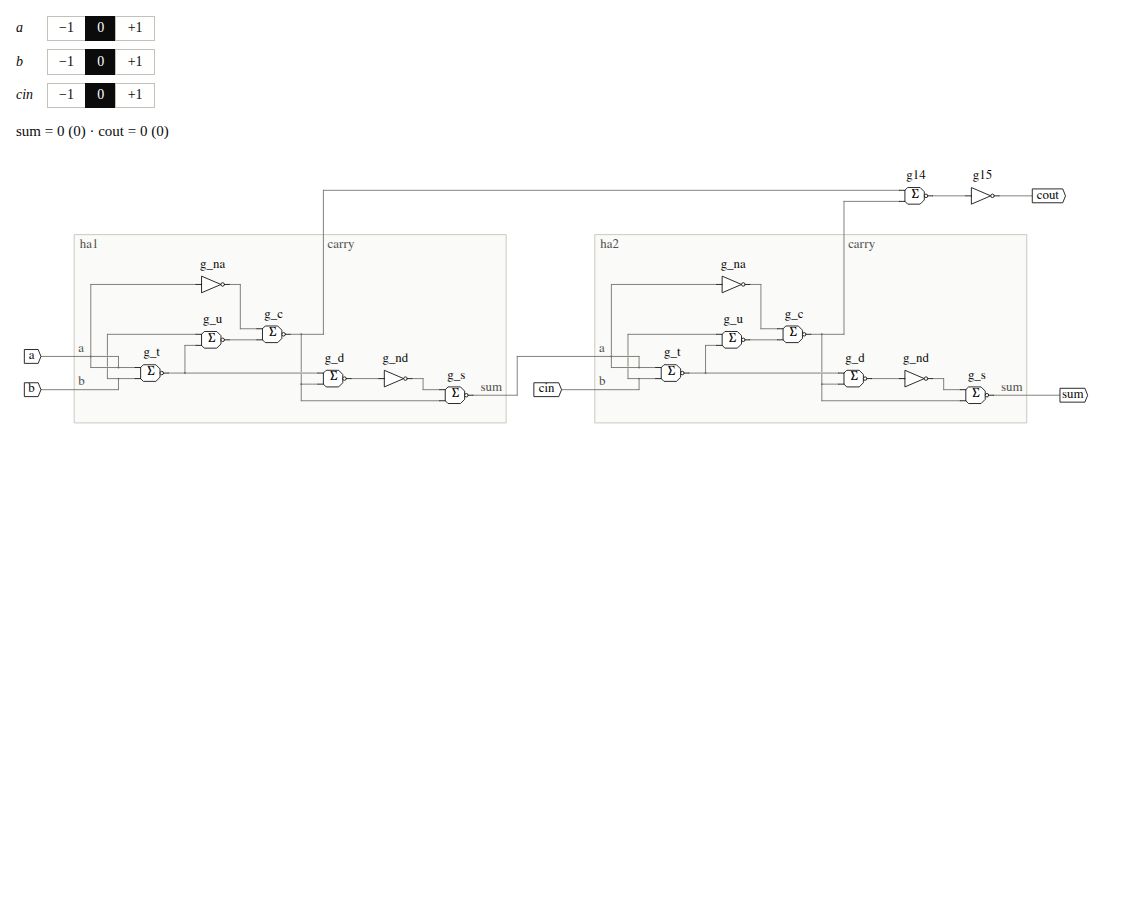

In [13]:
# 3-2 Logic synthesis
need("full_add_source", why="The HDL to synthesize is defined in 3-1.")
with step("Logic synthesis") as s:
    full_add_rtl = flow.loads(full_add_source).synthesize()
    s.done(" · ".join(f"{cell}×{n}" for cell, n in full_add_rtl.report()["cells"].items())
           + f" · all {full_add_rtl.equivalence['vectors']} input vectors equivalent")
bus_picker(full_add_rtl)

Multiplying two one-trit values (`*`) is much simpler. The product is always −1, 0 or +1, so **no carry is produced**. The product of a weight w and an input x is x itself for w = +1, its negation −x for w = −1, and 0 for w = 0. The synthesizer expands this multiplication into the same netlist as the taped-out circuit: **2 NAND, 1 NOR and 1 INV**.

In [14]:
# 3-3 HDL: one-trit product using *
mul_source = """
module mul(input trit w, x, output trit p);
  assign p = w * x;
endmodule
"""

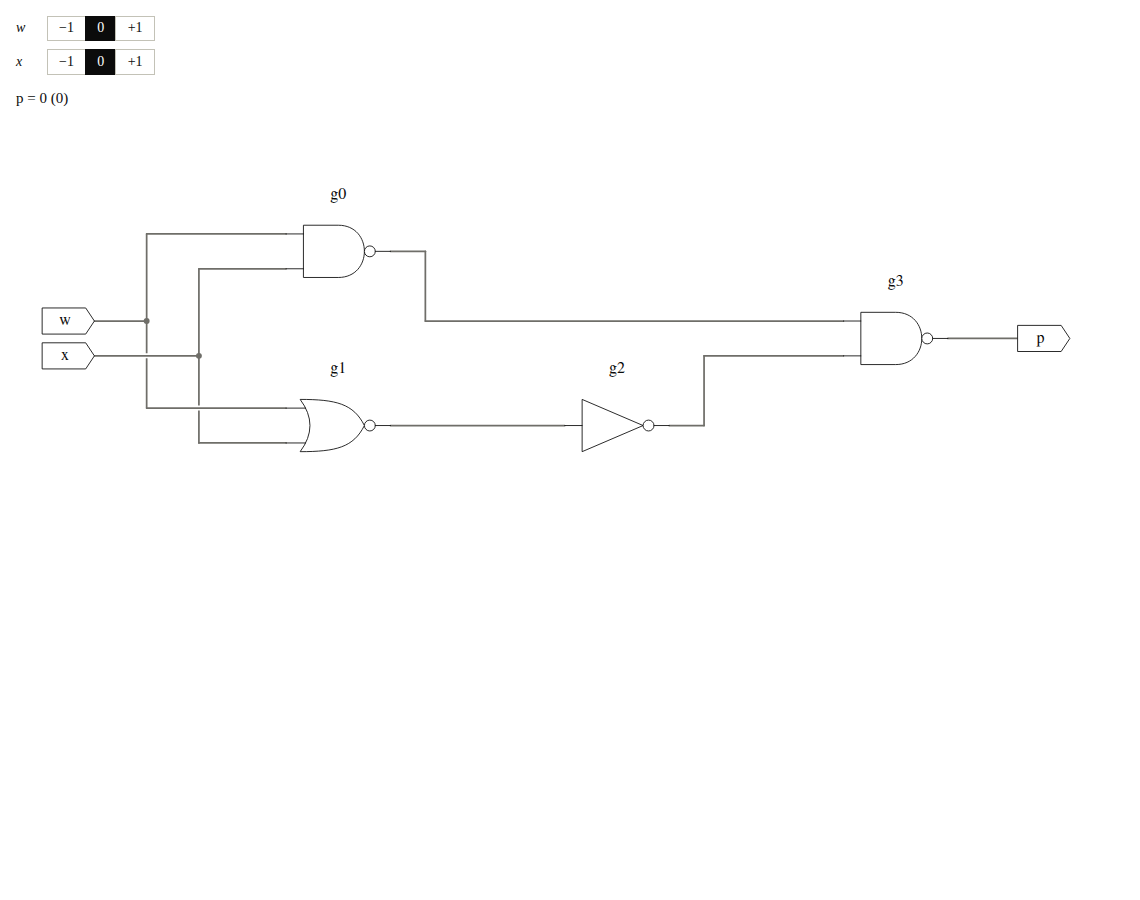

In [15]:
# 3-4 Logic synthesis
need("mul_source", why="The HDL to synthesize is defined in 3-3.")
with step("Logic synthesis") as s:
    mul = flow.loads(mul_source).synthesize()
    s.done(" · ".join(f"{cell}×{n}" for cell, n in mul.report()["cells"].items())
           + f" · all {mul.equivalence['vectors']} input vectors equivalent")
bus_picker(mul)

### 3.5 Selection: Mapping Conditional Logic

Conditional constructs such as `if-else`, `case` and the ternary operator `?:` are synthesized into selectors (multiplexers) that pass one of several candidates to the output according to a condition signal.

In binary logic the condition is either 0 or 1, so a simple AND-OR circuit makes a selector. In ternary logic, however, **the condition itself can be 0 (unknown)**, so the output for a 0 condition has to be defined and built into the circuit. TritFlow's logic synthesizer chooses between two kinds of selector depending on the condition.

The code cell below compares two ways of writing the same function: select a when op = +1 and b when op = −1.

In [16]:
# 3-5 HDL: two descriptions of selection
select_sources = {
"(op == 1't1) ? a : b": """
module sel_cmp(input trit a, b, op, output trit r);
  assign r = (op == 1't1) ? a : b;
endmodule
""",
"op ? a : b": """
module sel_raw(input trit a, b, op, output trit r);
  assign r = op ? a : b;
endmodule
""",
}

**A comparison as the condition: `op == 1't1`**　Let s be the result of the comparison. s is only ever true (+1) or false (−1), never 0; for op = 0 the comparison is false and b is selected. When the condition is guaranteed never to be 0, output r can take the same form as a binary AND-OR selector:

$$r = \max\bigl(\min(s,\ a),\ \min(-s,\ b)\bigr)$$

For s = +1, min(+1, a) = a and min(−1, b) = −1, so their max is a. For s = −1, the output is b by the same reasoning. min, max and negation are built from NAND, NOR and INV, respectively.

**The value itself as the condition: `op`**　When the signal `op` is used directly as the condition, op can be 0. The TritVerilog language specification defines the output for a 0 condition as the common value if a and b are equal, and 0 if they differ (multi-trit values are compared digit by digit). This behavior needs a ternary selector with one input for each of the three condition values (−1, 0, +1): MUX3.

,BUF,INV,NAND,NANY,NOR,TIEN,TIEP,TIEZ,Total,Equivalence check
(op == 1't1) ? a : b,,5,2,2,1,1,,,11,All 27 input vectors match
op ? a : b,1,11,6,6,5,1,1,1,32,All 27 input vectors match


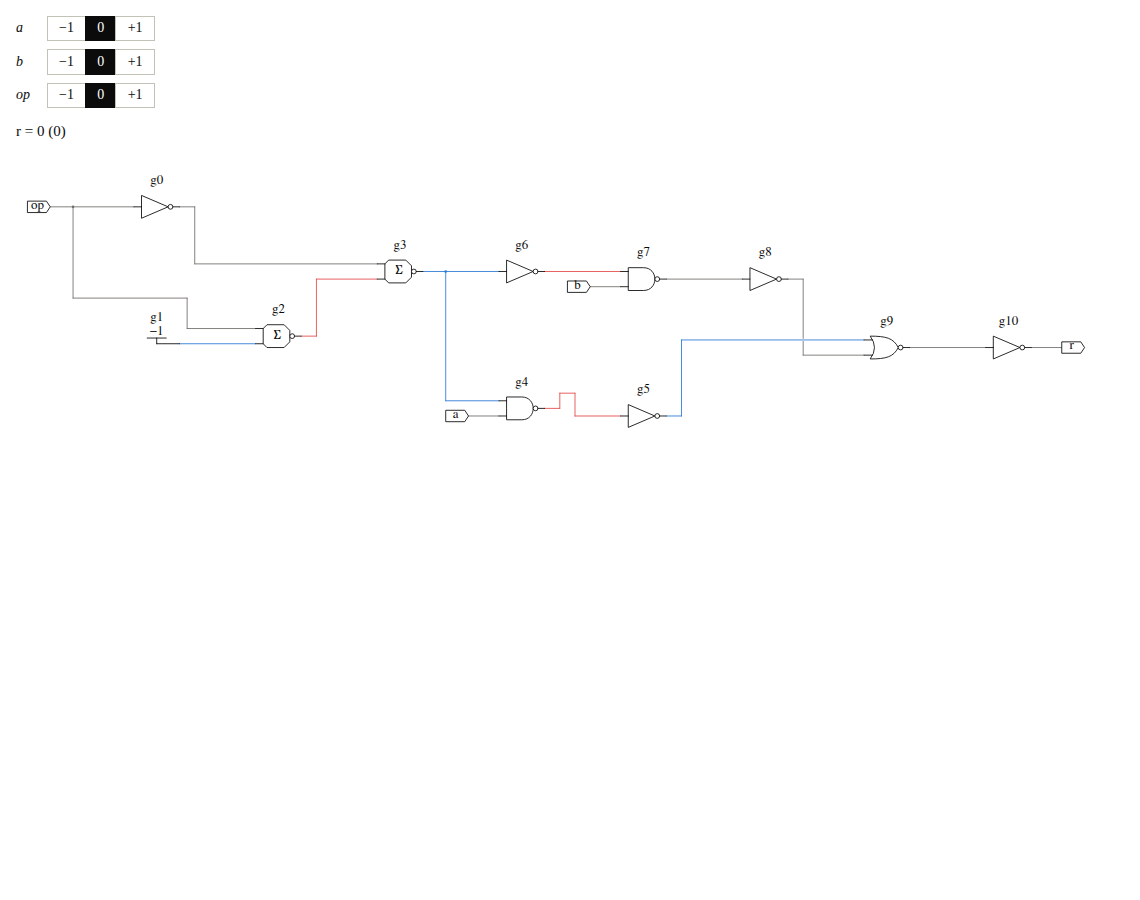

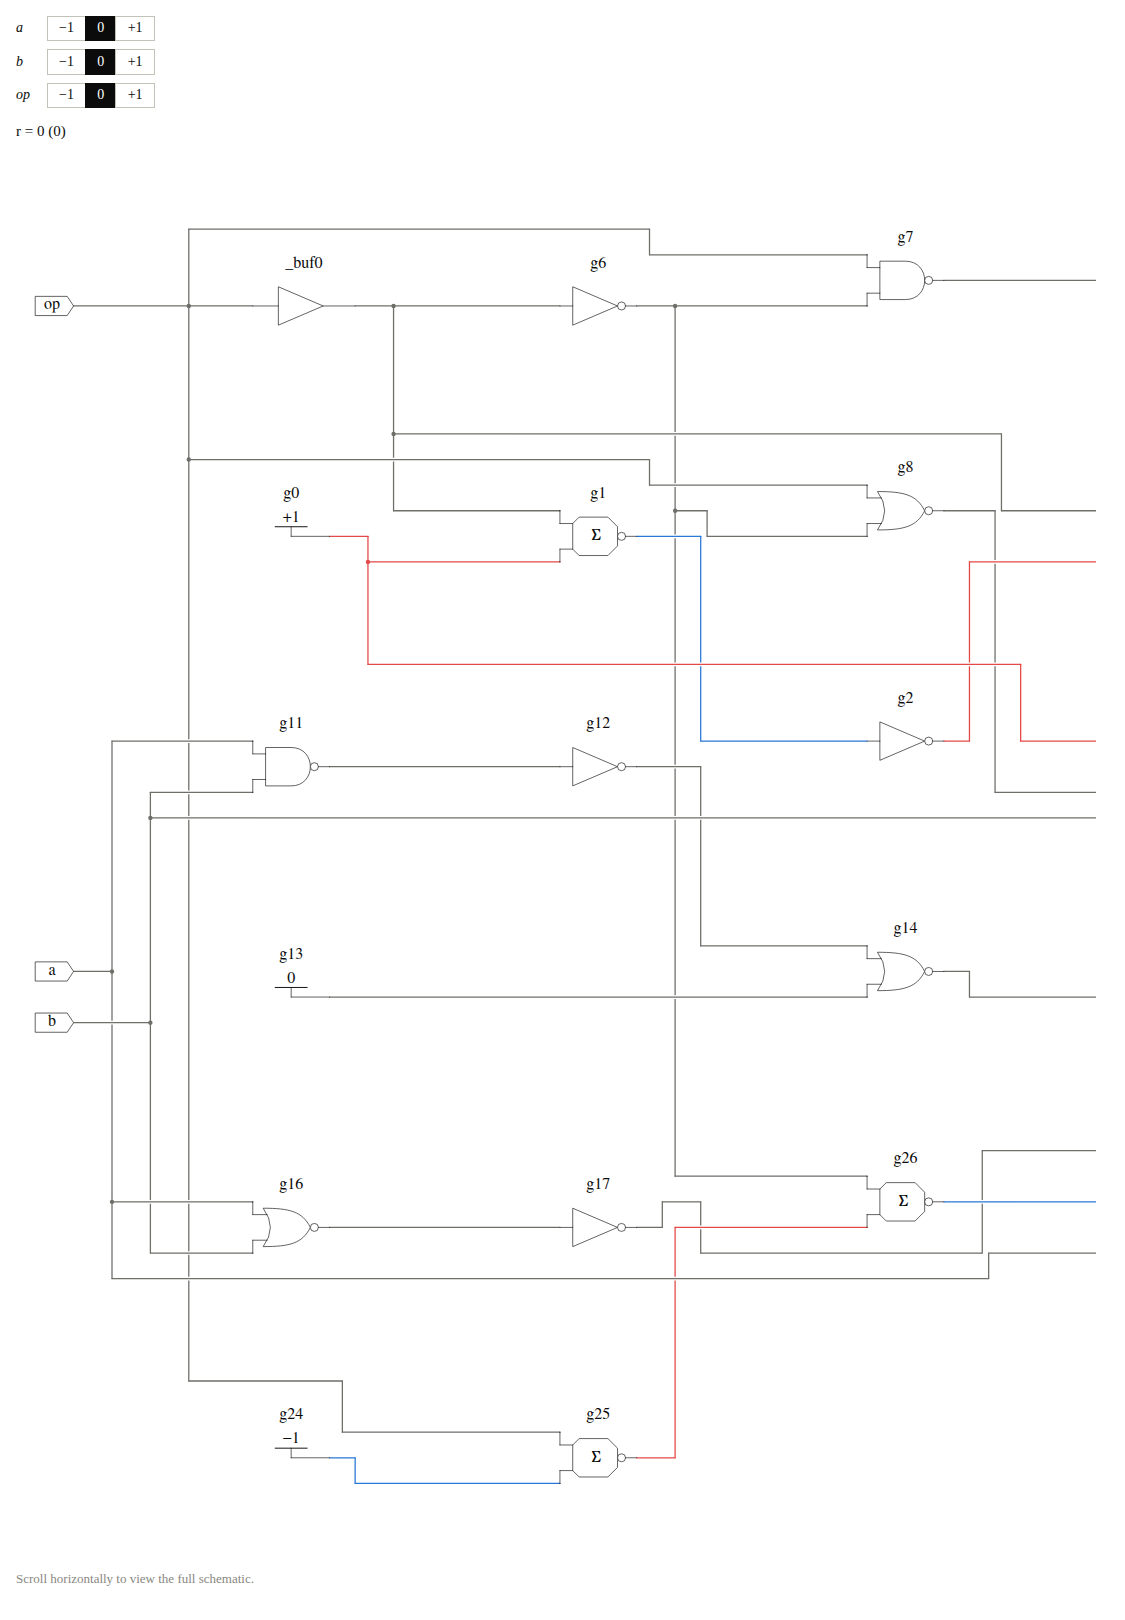

In [17]:
# 3-6 Synthesize and compare
need("select_sources", why="The HDL to synthesize is defined in 3-5.")
with step("Logic synthesis") as s:
    selects = {name: flow.loads(source).synthesize() for name, source in select_sources.items()}
    s.done(" · ".join(f"{name} {net.report()['total_cells']} cells" for name, net in selects.items()))
cell_counts(selects)
for net in selects.values():
    bus_picker(net)

The second description, which needs MUX3, uses more cells than the first. Whenever TritFlow's logic synthesizer can confirm on the intermediate representation that a condition never takes 0, it uses the first structure.

### 3.6 Equivalence Checking

To make logic synthesis trustworthy, TritFlow automatically checks after every synthesis run that the synthesized gate netlist means the same as the original HDL. It evaluates the HDL behavior (integer and truth-value evaluation) and the gate netlist (logic simulation from each cell's truth table) along two independent paths and compares every output.

Inputs of up to 12 trits are checked exhaustively (at most 3<sup>12</sup> = 531,441 combinations). Circuits with more than 12 input trits are checked with 100,000 pseudorandom test vectors from a fixed seed. The "all … input vectors equivalent" in the synthesis results so far comes from this check.

### 3.7 Application: Dot Product with Ternary Weights

The core operation of ternary-weight neural networks such as [BitNet b1.58](https://doi.org/10.48550/arXiv.2402.17764), mentioned at the start, is the dot product y = Σ<sub>i</sub> w<sub>i</sub>x<sub>i</sub> of ternary weights w<sub>i</sub> ∈ {−1, 0, +1} and inputs x<sub>i</sub>. BitNet b1.58 uses 8-bit inputs; here, the inputs are also restricted to one trit. The circuit the author taped out on OpenSUSI-TR10 is itself a one-trit multiply-accumulate circuit (X + A × B + C<sub>in</sub> = S + 3C<sub>out</sub>), one term of this dot product.

Here, the multiplier and adder from section 3.4 are combined into a four-term dot-product circuit (module name dot4), written in TritVerilog and synthesized. Each product w<sub>i</sub>x<sub>i</sub> lies between −1 and +1 and the four-term sum between −4 and +4, so output y fits in two trits (weights 3<sup>1</sup> and 3<sup>0</sup>).

In [18]:
# 3-7 HDL: four-term dot product with ternary weights
dot4_source = """
module dot4(input trit w0, w1, w2, w3, x0, x1, x2, x3, output trit [1:0] y);
  assign y = w0*x0 + w1*x1 + w2*x2 + w3*x3;
endmodule
"""

In [19]:
# 3-8 Logic synthesis
need("dot4_source", why="The HDL to synthesize is defined in 3-7.")
with step("Logic synthesis") as s:
    dot4 = flow.loads(dot4_source).synthesize()
    s.done(" · ".join(f"{cell}×{n}" for cell, n in dot4.report()["cells"].items())
           + f" · all {dot4.equivalence['vectors']} input vectors equivalent")

In the synthesized netlist, each of the four multipliers is built from 2 NAND, 1 NOR and 1 INV (16 cells in total), and the adder that sums them from one full adder and two half adders (21 NANY and 9 INV).

## 4. Place and Route

Place and route turns the netlist synthesized in chapter 3 into GDS: it places the cells under the geometric rules of the TR-1um PDK and connects them with two metal layers. This chapter walks through TritFlow's place-and-route tool on the four-term dot-product circuit synthesized in section 3.7.

### 4.1 Why a Custom Place-and-Route Tool

Place and route is a geometric connection problem that does not depend on signal values, so in principle binary EDA tools such as OpenROAD could be reused. For TR-1um, a port to LibreLane is in fact under way ([luyanaa/TR-1um](https://github.com/luyanaa/TR-1um)).

Using existing binary EDA tools unchanged for ternary design, however, runs into three technical obstacles.

1. **Only two metal layers**: TR-1um is a 1 µm process with just two metal layers for routing, the first (M1) and the second (M2). Power distribution and signal routing must share them.
2. **Three power rails, and the limits of Liberty**: every ternary cell must carry three power rails, VDD (+5 V), VMID (0 V) and VSS (−5 V), continuously without gaps. Liberty, the standard format for cell characteristics, cannot describe ternary logic or ternary transition characteristics.
3. **Static current in ternary cells**: ternary cells draw static current through their resistive dividers while they output 0 V. If high-current cells cluster on one rail, the current exceeds what the power wiring allows.

To solve these problems, TritFlow implements its own lightweight place-and-route tool, which leaves dedicated routing channels between cell rows and routes on two layers.

### 4.2 Placement: Simulated Annealing

Placement alternates rows of cells with routing channels between them.

1. **Initial placement**: following the signal flow from the circuit's inputs to its outputs, each cell goes into whichever row is currently shortest.
2. **Simulated annealing**: starting from the initial placement, 600 annealing steps improve it gradually. Each step randomly performs one of the three moves below. A move that lowers the cost is accepted; one that raises it is accepted with a probability that depends on the temperature, which falls as the steps proceed.
   - **Swap (60%)**: exchange the positions of two cells.
   - **Move (30%)**: move one cell to another row or position.
   - **Mirror (10%)**: flip a cell between its normal orientation (R0) and its left-right mirror (MY) to bring its pins closer to nearby wiring.
3. **Cost function and current constraint**: the cost is the half-perimeter wire length (HPWL), the sum over all nets of the half-perimeter of the box bounding each net's terminals, plus a small weight times the width of the longest row. The static current of the cells is also summed per row, and any candidate placement that exceeds the current limit of a power rail is rejected by giving it infinite cost.

### 4.3 Routing: Maze Search

Once the cells are placed, the signal nets are routed on the routing grid (6 µm pitch). The basic strategy is orthogonal two-layer routing: M1 runs horizontally inside the channels, and M2 runs vertically and may pass over cells.

1. **A\* search**: starting with the nets that have the most terminals and span the widest area, each net is connected along a shortest path through vias (V1) by the A\* algorithm.
2. **Rip-up and retry**: if a later net is blocked by existing wiring and cannot be connected, all wiring is removed and routing restarts from scratch, with the failed net first and the remaining order shuffled. Up to 8 attempts are made, including the first.
3. **Channel expansion**: if routing is still incomplete after 8 attempts, the routing channels get more tracks and routing is tried again (up to 5 times).
4. **Power trunks**: vertical M2 power trunks are added to feed the M1 rails of every row.

Running the code cell below performs place and route. While it runs, the placement and routing are drawn live; when it finishes, the drawing is replaced by a figure with sliders that step through the placement improvement and the order in which the nets were routed.

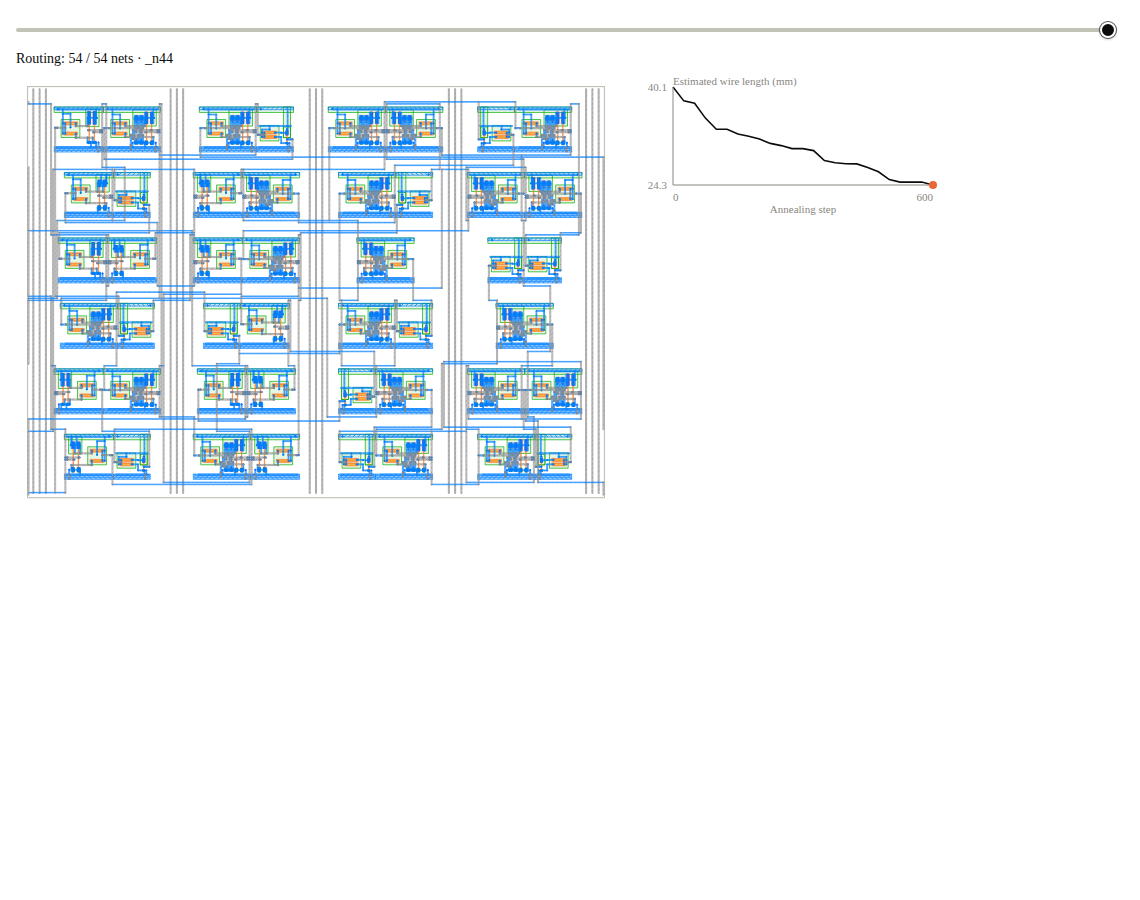

In [20]:
# 4-1 Place and route
need("dot4", why="The dot-product netlist is synthesized in 3-8.")
with step("Place and route", view=LayoutView()) as s:
    dot4_layout = dot4.place_and_route(output_dir=BUILD/"dot4", seed=0)
    stats = dot4_layout.stats
    s.done(f"{stats['instance_count']} cells · {stats['row_count']} rows · {stats['die_size_um'][0]:.0f} × {stats['die_size_um'][1]:.0f} µm · "
           f"Estimated wire length {stats['hpwl_before_um']/1e3:.1f} → {stats['hpwl_after_um']/1e3:.1f} mm · Vias: {stats['via_count']}",
           picture=replay(dot4_layout))

The GDS layout of the finished dot-product circuit is shown below.

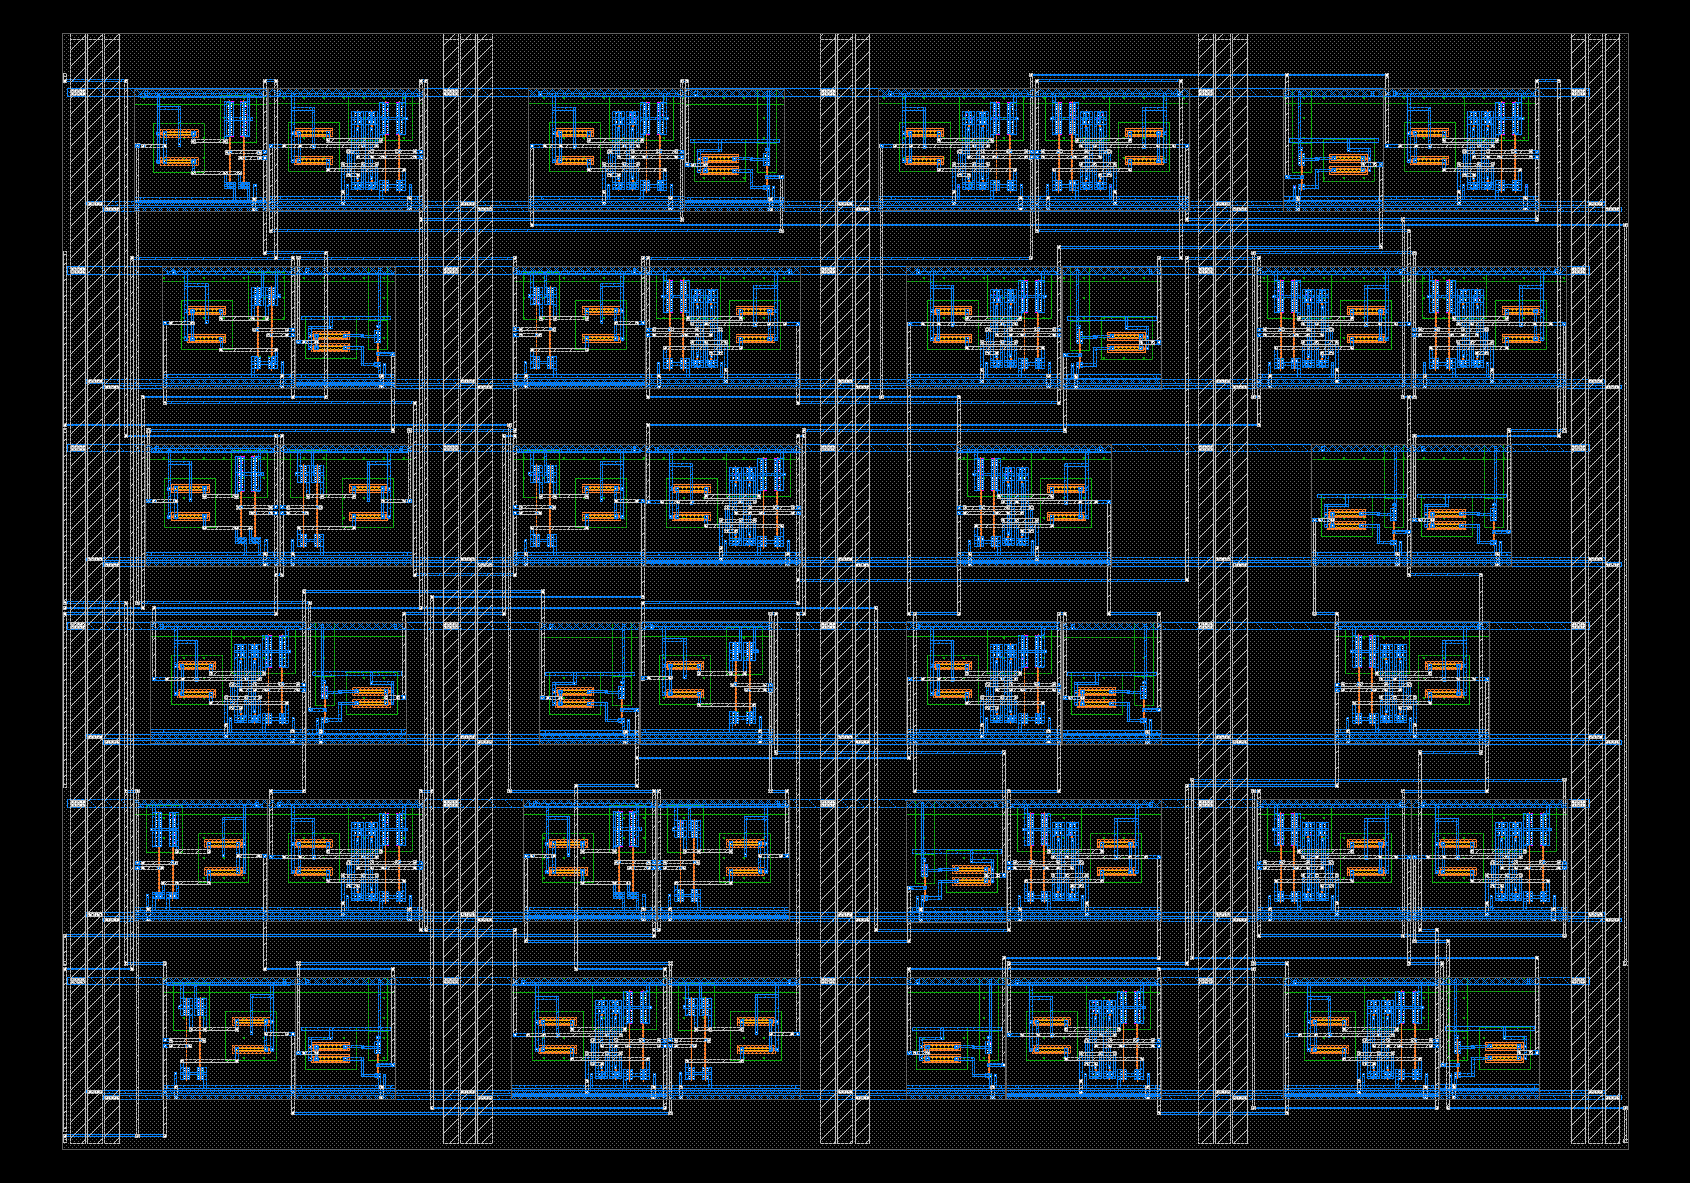

In [21]:
# 4-2 GDS
need("dot4_layout", why="The GDS to display is generated in 4-1.")
gds_viewer(dot4_layout.gds_path)

## 5. Verification and Timing

This chapter checks the dot-product GDS from chapter 4 with the PDK's official physical-verification decks, then evaluates its function and speed by post-layout simulation that includes wire capacitance. It also compares a ternary static timing analysis (STA), which estimates delay without SPICE, against SPICE.

### 5.1 DRC and LVS

The official KLayout decks of the OpenSUSI TR-1um PDK check whether the finished layout meets the manufacturing rules of Tokai Rika's fab.

1. **DRC (Design Rule Check)**: checks for violations of geometric rules such as minimum wire width, minimum spacing, minimum area and enclosure.
2. **LVS (Layout Versus Schematic)**: extracts the transistor connectivity (netlist) from the GDS and compares it with the netlist from logic synthesis, covering not only the device connections but also the connections to the power rails (VDD/VMID/VSS).

In [22]:
# 5-1 DRC and LVS
need("dot4_layout", why="The GDS to verify is generated in 4-1.")
with step("DRC") as s:
    dot4_drc = dot4_layout.drc()
    s.done(f"Violations: {dot4_drc['violations']}")
with step("LVS") as s:
    dot4_lvs = dot4_layout.lvs()
    s.done("Matched" if dot4_lvs["matched"] else "Mismatch")

### 5.2 Extraction and Wire Capacitance

The current OpenSUSI TR-1um PDK has no official deck for parasitic extraction (PEX). TritFlow therefore estimates each net's wire capacitance to the substrate from the wiring geometry of the LVS-matched GDS.

The estimate takes the area and perimeter of the M1 and M2 shapes and computes the wire capacitance from the following assumed values, which are not calibrated against the PDK.

- relative permittivity of the insulator (SiO<sub>2</sub>): 3.9
- height above the substrate: 1 µm for M1, 2 µm for M2
- fringe capacitance at wire edges: 0.02 fF/µm for both layers

Coupling capacitance between wires and wire resistance are ignored, and each net's capacitance is added to the SPICE netlist as a lumped capacitor.

In [23]:
# 5-2 Extraction and wire capacitance
need("dot4_lvs", why="Extraction uses the LVS-matched GDS from 5-1.")
with step("Extraction and wire capacitance") as s:
    dot4_extracted = dot4_layout.extract()
    dot4_wires = dot4_layout.result.net_parasitics()
    s.done(f"Device netlist · Wire capacitance added to {len(dot4_wires['nets'])} signal nets")
wire_table(dot4_wires)

Net,Wire capacitance (fF)
_n33,227.5
y[0],204.6
_n11,170.0
x3,151.7
x1,138.8
_n9,131.1
_n30,130.6
_n8,130.4
Total over 54 nets,4157


### 5.3 Ternary Delay

In binary integrated circuits, propagation delay is usually measured at the moment the output crosses half the supply voltage.

**This definition does not work for ternary circuits**, because the midpoint of the supply, 0 V (VMID), is itself the voltage of logic 0. When an output switches from −1 (−5 V) to +1 (+5 V), for example, the waveform always passes near 0 V on the way. Measuring at the midpoint crossing would declare the transition finished while it is still in progress.

TritFlow therefore defines delay as **settling time**.

> **Ternary delay**: the time from when the input starts to change until the output enters the acceptance band (±0.5 V) around its final target voltage (−5 V, 0 V or +5 V) and stays there.

The cell below fixes the dot-product circuit's weights at w = (+1, −1, +1, +1) and runs post-layout simulation while input x steps through a sequence that produces carries. This mirrors inference, in which trained weights are fixed. Arrows on the waveforms mark the settling time of each output's slowest transition.

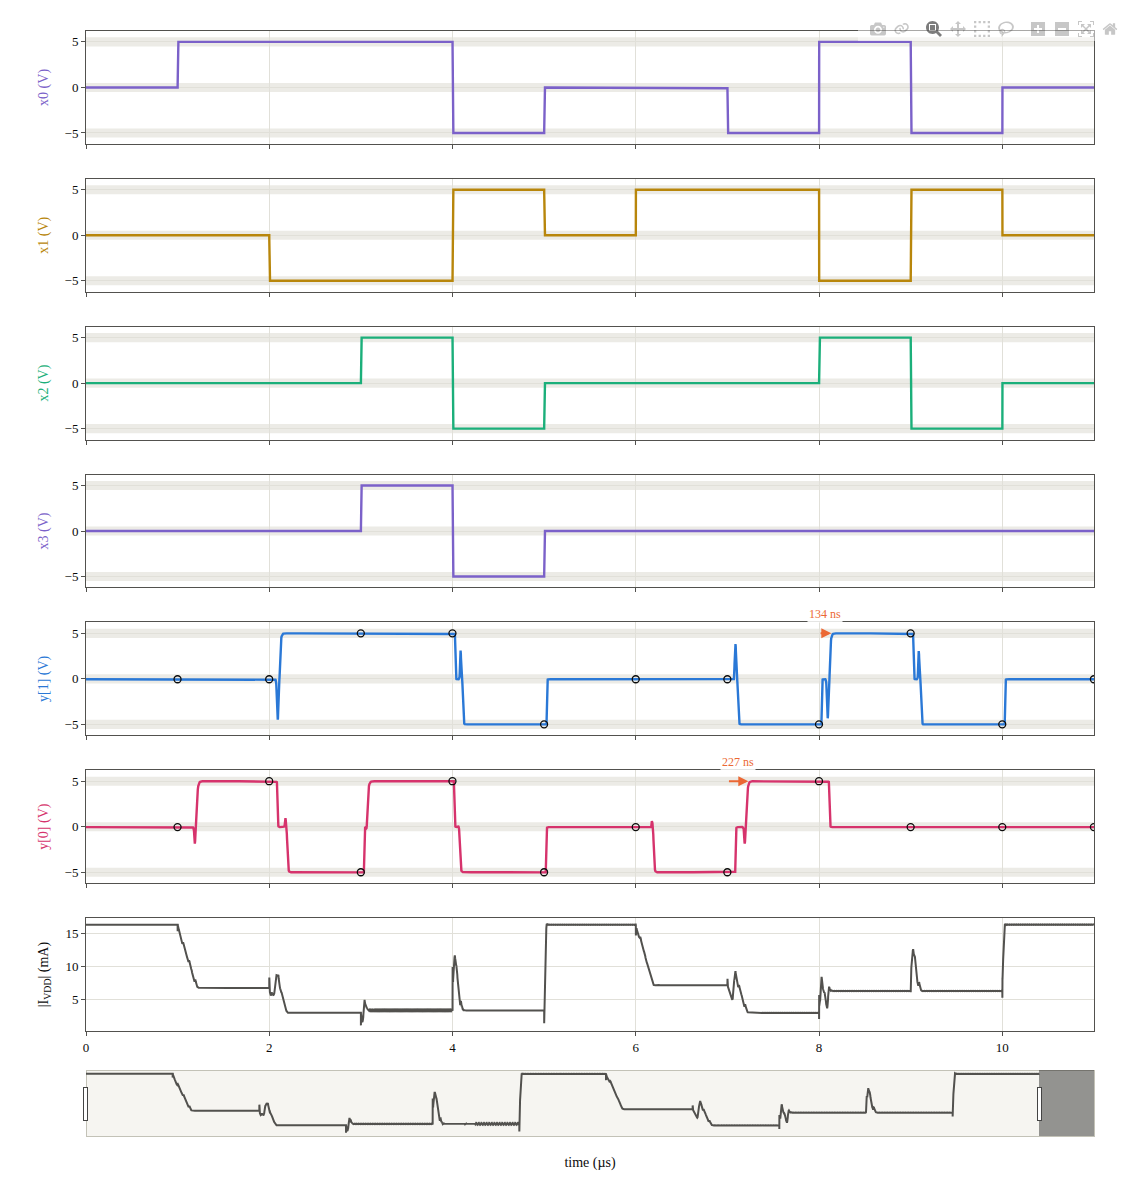

In [24]:
# 5-3 Post-layout simulation
need("dot4_extracted", why="The circuit to simulate is extracted in 5-2.")
from tritflow.sim.postlayout import logical_nodeset
dot4_inputs = [p.name for p in dot4.ports if p.dir == "input"]
weights = (+1, -1, +1, +1)
activations = [(0, 0, 0, 0), (1, 0, 0, 0), (1, -1, 0, 0), (1, -1, 1, 1), (-1, 1, -1, -1), (0, 0, 0, 0),
               (0, 1, 0, 0), (-1, 1, 0, 0), (1, -1, 1, 0), (-1, 1, -1, 0), (0, 0, 0, 0)]
def operands(x):
    """The circuit's input trits for the fixed weights and the activations x, in port order."""
    values = {f"w{i}": w for i, w in enumerate(weights)} | {f"x{i}": v for i, v in enumerate(x)}
    return tuple(values[p] for p in dot4_inputs)
dot4_vectors = [operands(x) for x in activations]
with step("ngspice") as s:
    dot4_post = dot4_extracted.simulate(dot4_vectors, load=100e-15, hold_s=1e-6, step_s=5e-9, edge_s=1e-9,
                                        temperature_c=27, timeout=600, workdir=BUILD/"dot4"/"postlayout",
                                        nodeset=logical_nodeset(dot4, dot4_lvs["report"], dot4_inputs, dot4_vectors[0]))
    s.done("within the ±0.5 V band in every interval" if dot4_post["measurements"]["passed"] else "outside the band in some intervals")
display(HTML(scope_figure(dot4_post, settle=True).to_html(include_plotlyjs="cdn", full_html=False,
                                                         config={"displaylogo": False, "scrollZoom": True})))
transient_conditions(dot4_post, load_f=100e-15)

### 5.4 Ternary STA

Binary STA has only two transitions to consider, rising and falling. Ternary logic has three states and therefore six transitions (−1 → 0, −1 → +1, 0 → −1, 0 → +1, +1 → −1 and +1 → 0), and a cell's propagation delay differs for each.

TritFlow's ternary STA looks up, for each cell, tables of propagation delay and output slew measured with SPICE and indexed by input transition type, input slew and output load capacitance.

- **Stage propagation delay**: the time between the input's midpoint crossing (halfway between the voltages before and after the transition) and the output's midpoint crossing, summed stage by stage.
- **Settling at the output**: at the final output stage, the time from the midpoint crossing until the output enters the ±0.5 V acceptance band is added, so the result matches the settling time defined in section 5.3.

The INV table for an input slew of 1 ns is shown below.

In [25]:
# 5-4 INV delay table
delay_table("INV")

INV has one input, so its table has six rows. Two-input cells such as NAND and NANY have one table for each value of the other input, plus one for both inputs switching together. STA estimates and SPICE are then compared for the same input sequence as in section 5.3.

In [26]:
# 5-5 Ternary STA and SPICE comparison
need("dot4_post", why="The SPICE results for comparison are computed in 5-3.")
from tritflow.sta import analyze
states = [dict(zip(dot4_inputs, v)) for v in dot4_vectors]
with step("Ternary STA") as s:
    dot4_timing = analyze(dot4, vector_pairs=list(zip(states, states[1:])),
                          wire_caps={n: e["wire_capacitance_f"] for n, e in dot4_wires["nets"].items()},
                          output_load_f=100e-15, input_transition_s=1e-9)
    s.done(f"{len(dot4_timing.arrival)} outputs")
timing_table(dot4_post, dot4_timing)
note("STA conditions: input sequence from 5-3, output load 100 fF, input slew 1 ns, wire capacitance extracted in 5-2.")

Output,SPICE (ns),STA (ns),Difference
y[1],133.6,120.7,−10%
y[0],227.4,219.9,−3%


## 6. Evaluation and Applications

Chapter 5 verified the four-term dot-product circuit with post-layout simulation and ternary STA. This chapter first evaluates how area, delay and static power change with the number of terms N. It then reruns the same flow after editing the HDL, and finally builds a top-level layout with the MPW frame and I/O pads.

### 6.1 Dot-Product Size and Area

The test circuit is the dot product of ternary weights and inputs, y = w<sub>0</sub>x<sub>0</sub> + … + w<sub>N−1</sub>x<sub>N−1</sub>, with N = 2, 4, 8 and 16 terms.

Output y has the fewest digits that can represent −N through +N: 2 trits for N = 2 and 4, 3 trits for N = 8, and 4 trits for N = 16. The weights stay HDL inputs but are fixed in simulation to repetitions of (+1, −1, +1, +1). The addition is written the same way as in section 3.7 and synthesized without any structural changes for different term counts.

The cell below shows the recorded place-and-route and verification results for each size. Area is taken from the outline of the routed die.

In [27]:
# 6-1 Dot-product size and area
from scale_views import load_scaling, scaling_table, synthesis_table
# The full campaign takes a long time (N=16 analysis and the N=32 routing attempt).
RECOMPUTE_SCALING = False #@param {type:"boolean"}
dot_scaling = load_scaling(recompute=RECOMPUTE_SCALING)
display(synthesis_table(dot_scaling), scaling_table(dot_scaling))
for attempt in dot_scaling.get("optional_attempts", []):
    stage = "incomplete at place and route" if not attempt.get("pnr") else "incomplete at verification"
    note(f"Optional attempt N={attempt['n']} is {stage}; excluded from the comparisons below.")
for row in dot_scaling["rows"]:
    options = row["conditions"].get("pnr_options", {})
    if options:
        note(f"N={row['n']} place and route overrides: "
             f"inter-row channel tracks {options['channel_tracks']}, "
             f"permitted current per 1 µm of M1 width {options['current_density_a_per_um']*1e3:g} mA.")
conditions = dot_scaling["conditions"]
holds = ", ".join(f"N={row['n']}: {row['conditions']['hold_s']*1e6:g} µs"
                  for row in dot_scaling["rows"])
note(f"Recorded conditions: ngspice-{dot_scaling['provenance']['simulator']['version']}, "
     f"PDK {dot_scaling['provenance']['pdk']['qualified_commit'][:7]}, "
     f"{conditions['temperature_c']:g} °C, supplies +5 / 0 / −5 V. "
     f"Output load {conditions['load_f']*1e15:g} fF, input slew {conditions['edge_s']*1e9:g} ns, "
     f"maximum time step {conditions['step_s']*1e9:g} ns. Hold time per state: {holds}.")

Terms N,Output trits,INV,NAND,NANY,NOR,Input vectors checked,Equivalence
2,2,4,4,5,2,Exhaustive 81,Equivalent
4,2,13,8,21,4,"Exhaustive 6,561",Equivalent
8,3,35,16,63,8,"Random 100,000",Equivalent
16,4,92,32,175,16,"Random 100,000",Equivalent


Terms N,Cells,Die sizemm × mm,Die areamm²,Rows,HPWLmm,Routed lengthmm,Signal vias,Place and routes,DRC / LVS
2,15,0.61 × 0.87,0.53,5,3.95,8.27,107,1.73,0 / Matched
4,46,1.69 × 1.21,2.04,6,24.30,40.44,329,2.98,0 / Matched
8,122,2.16 × 3.05,6.60,13,167.86,236.37,1146,35.99,0 / Matched
16,315,5.51 × 3.89,21.45,13,832.90,"1,230.38",3320,48.55,0 / Matched


### 6.2 Static and Time-Average Power

Ternary CMOS logic gates draw static current, even with no input switching, in states where a resistive divider holds 0 V. NANY cells, however, also have states in which the series MOS paths to VDD and VSS are cut off and a clamp to VMID provides the 0 V output.

Static power is computed with SPICE from the DC operating points of the states in the recorded input sequence. The time-average supply power excludes the power delivered by the input voltage sources.

Terms N,Cells,|I(VDD)|mA · x=0,|I(VSS)|mA · x=0,Static powermW · x=0,Time averagemW,Static/cellmW · x=0,Average/cellmW,DC rangemW,Hold timeµs/interval
2,15,5.04,5.04,50.41,21.72,3.361,1.448,4.07–50.41,1.00
4,46,16.35,16.35,163.48,85.80,3.554,1.865,29.51–163.48,1.00
8,122,45.21,45.21,452.08,229.51,3.706,1.881,86.92–452.08,1.00
16,315,120.02,120.02,"1,200.19",638.63,3.810,2.027,"336.76–1,200.19",1.25


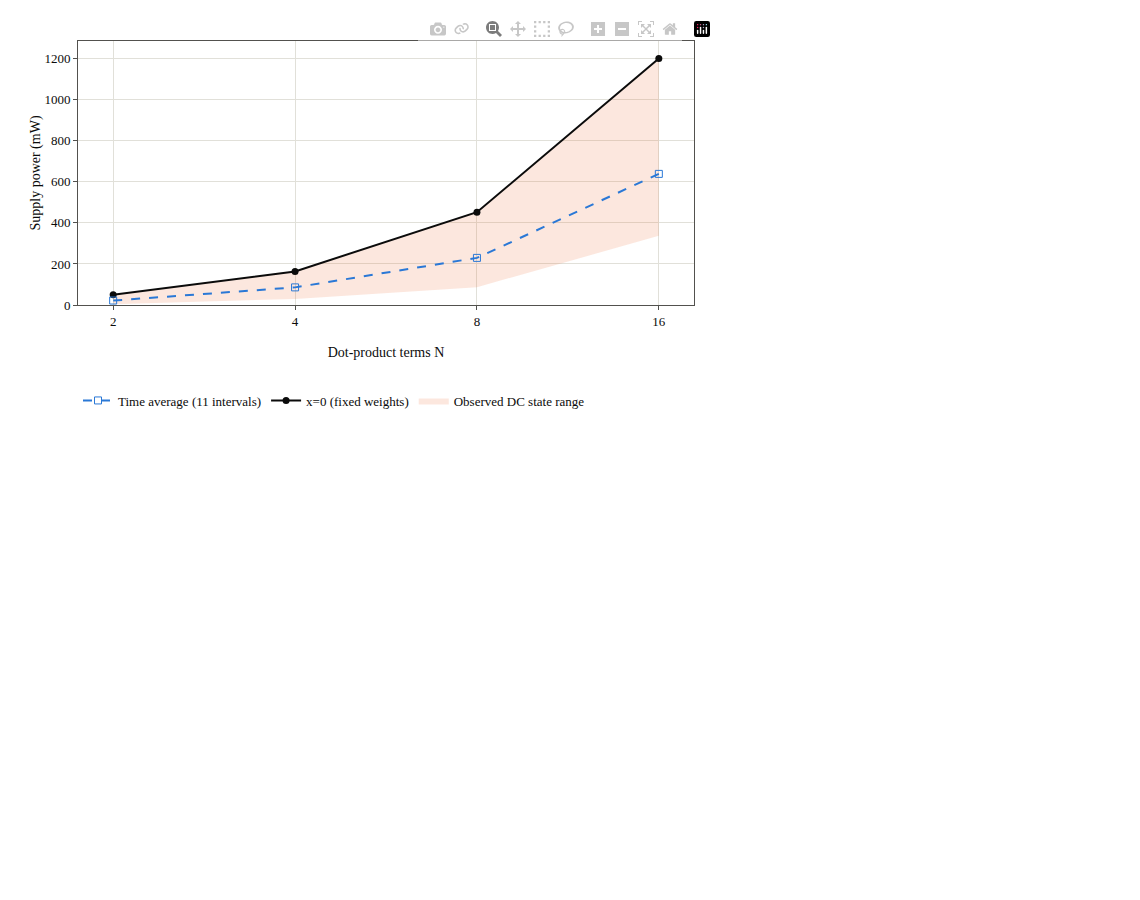

In [28]:
# 6-2 Static current and power
need("dot_scaling", why="The recorded data is loaded in 6-1.")
from scale_views import power_table, power_figure
power_plot = power_figure(dot_scaling)
power_plot.update_yaxes(title_text="Supply power (mW)")
display(power_table(dot_scaling), power_plot)

### 6.3 STA and SPICE

For each size, with the weights fixed, an input sequence that creates and clears positive and negative carries is applied, and the delay predicted by ternary STA is compared with the transient delay from SPICE. The four-term sequence differs from the one in chapter 5. STA and SPICE get the same input transitions, input slew, output load and wire capacitance. The delay compared is each output's maximum settling time over the sequence.

The effect of wire capacitance on delay is also examined. Device parasitics and the 100 fF output load are kept in both cases, and only the estimated wire capacitance is removed. STA is compared at every size, and SPICE at four terms.

In the 16-term circuit, some NANY loads exceed the upper limit of the characterization tables (2 pF), reaching up to 2.862 pF, so STA extrapolates the delay linearly in load capacitance.

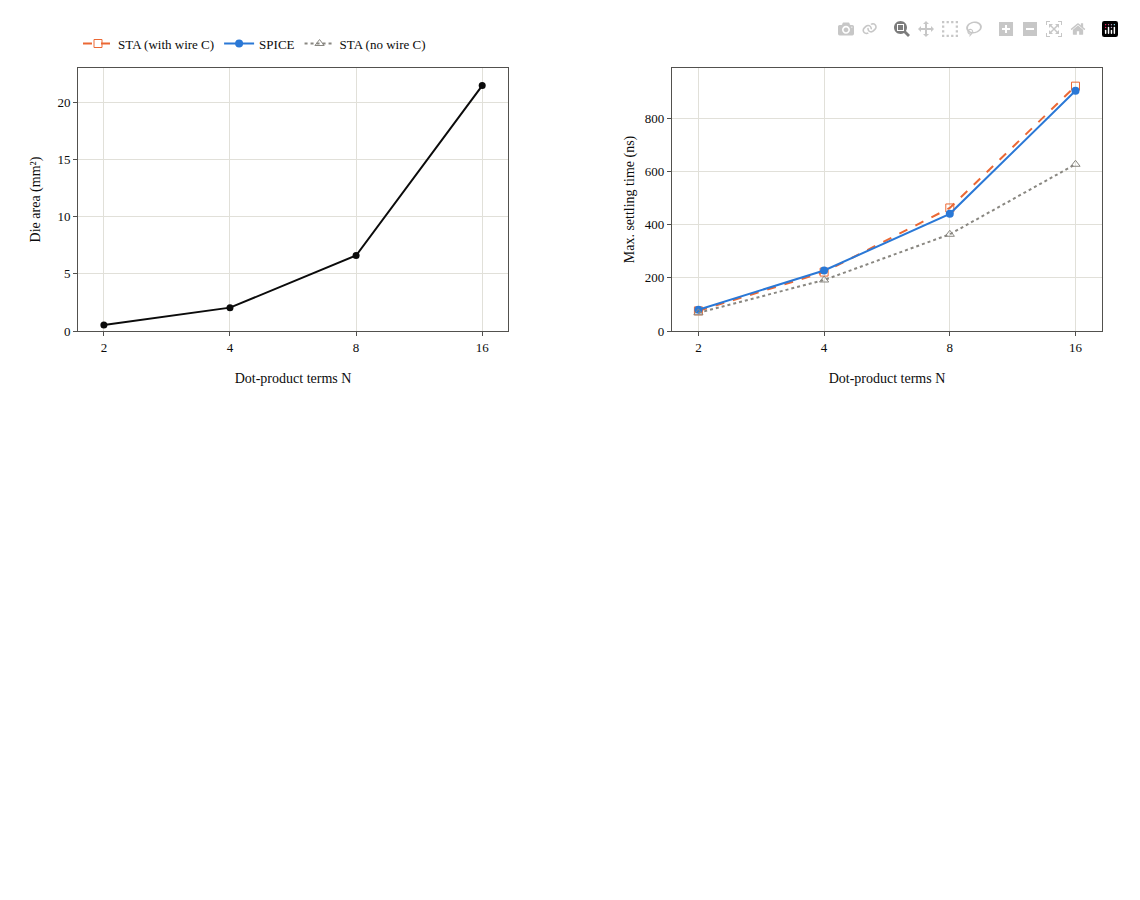

N,Output,"STA, no wire Cns","STA, with wire Cns",Increase%,"SPICE, no wire Cns","SPICE, with wire Cns",Increase%,STA error%
2,y[1],56.2,62.9,11.9,—,80.0,—,-21.3
2,y[0],68.1,75.6,11.0,—,79.7,—,-5.0
4,y[1],106.1,122.5,15.4,113.1,128.6,13.7,-4.8
4,y[0],191.5,221.3,15.5,199.7,227.2,13.8,-2.6
8,y[2],363.3,462.2,27.2,—,432.3,—,6.9
8,y[1],333.9,422.3,26.5,—,397.0,—,6.4
8,y[0],348.3,437.0,25.5,—,440.2,—,-0.7
16,y[3],626.3,919.7,46.9,—,902.2,—,1.9
16,y[2],596.9,880.5,47.5,—,868.6,—,1.4
16,y[1],567.9,835.0,47.0,—,828.9,—,0.7


In [29]:
# 6-3 STA and SPICE
need("dot_scaling", why="The recorded data for comparison is loaded in 6-1.")
from scale_views import scaling_figure, layout_penalty_table
display(scaling_figure(dot_scaling), layout_penalty_table(dot_scaling))

### 6.4 Editing HDL and Rerunning the Flow

Writing the inference weights into the HDL as constants lets logic synthesis simplify the multipliers to match those weights. The cell below rewrites the TritVerilog of the dot-product circuit from section 3.7 with its weights fixed at (+1, −1, +1, +1). Even with the expression and the input and output declarations changed, the same cell runs logic synthesis, place and route, DRC/LVS, wire-capacitance estimation and post-layout simulation in sequence.

In [30]:
# 6-4 Edit HDL
reuse_source = """
module dot4_fixed(input trit x0, x1, x2, x3, output trit [1:0] y);
  assign y = x0 - x1 + x2 + x3;
endmodule
"""

The SPICE transient analysis checks every combination when there are at most 27 states; otherwise it checks 11 representative states, such as the zero input, all inputs at −1 or at +1, alternating signs, and a single input at ±1. The expected outputs come from evaluating the HDL, not from the synthesized netlist.

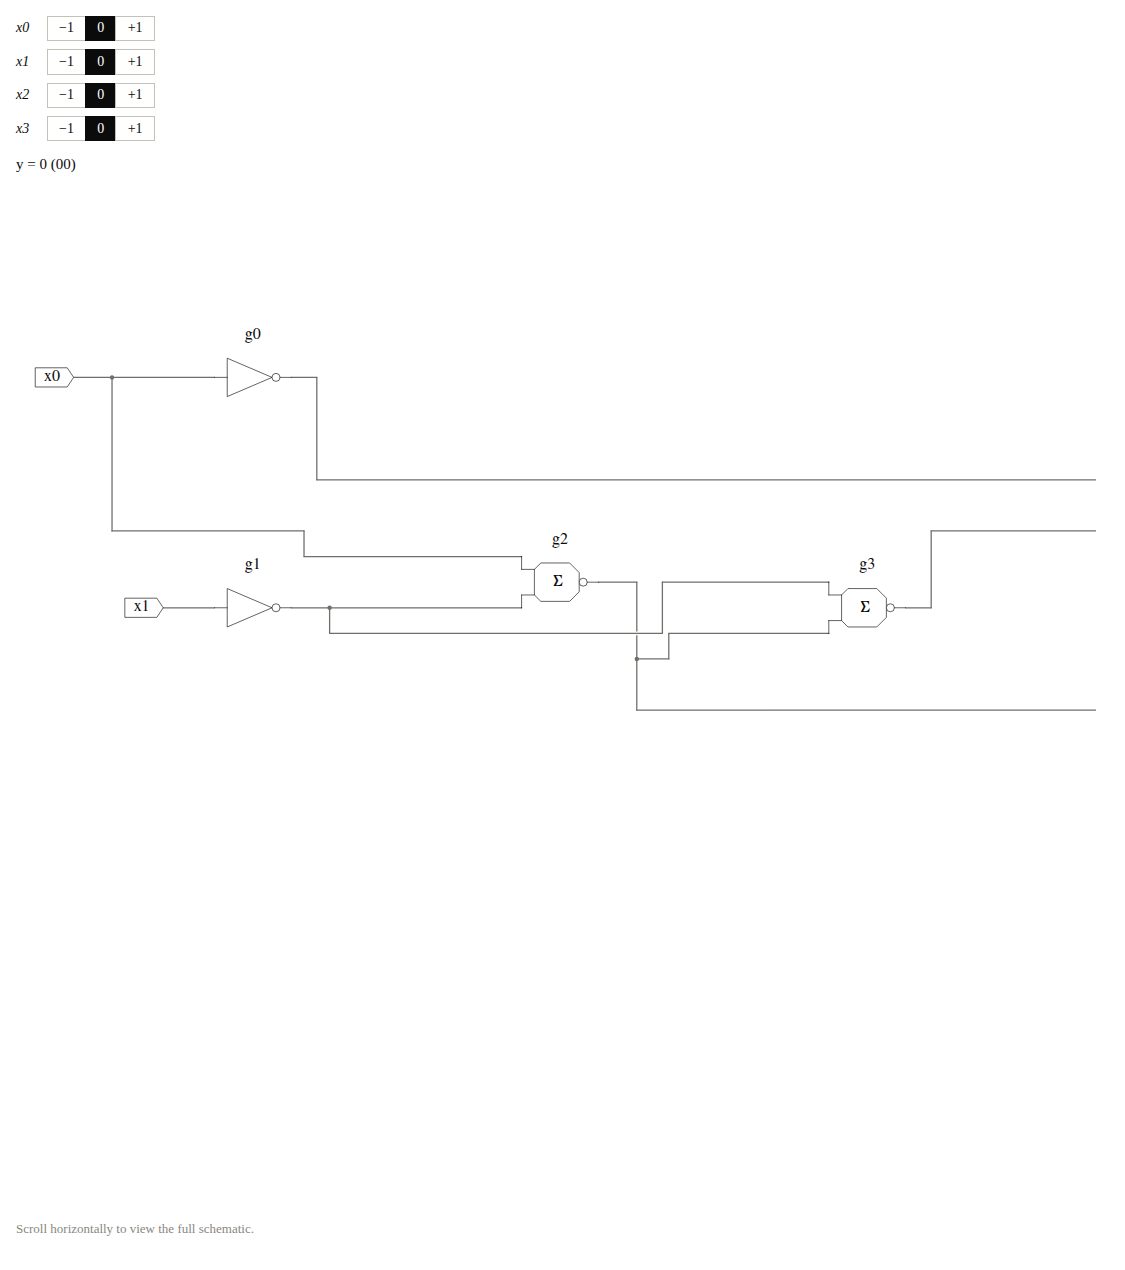

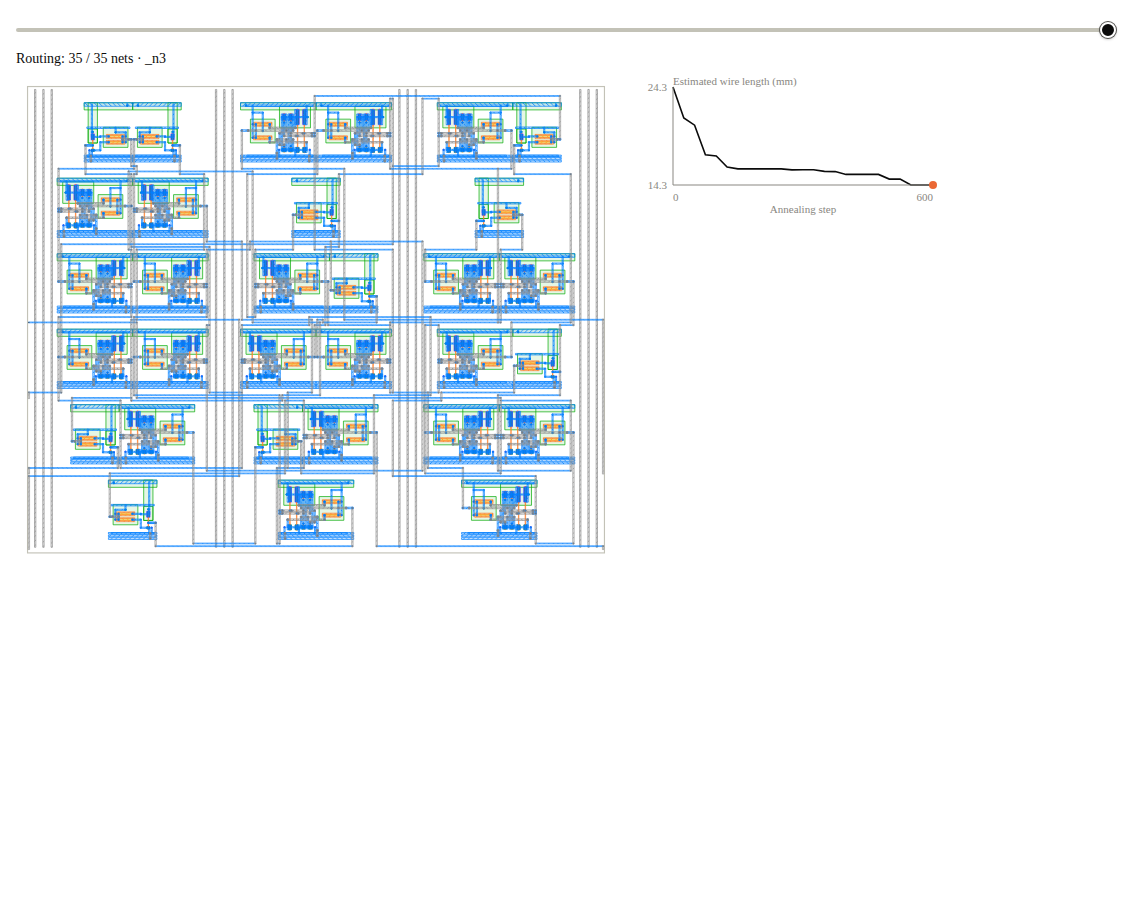

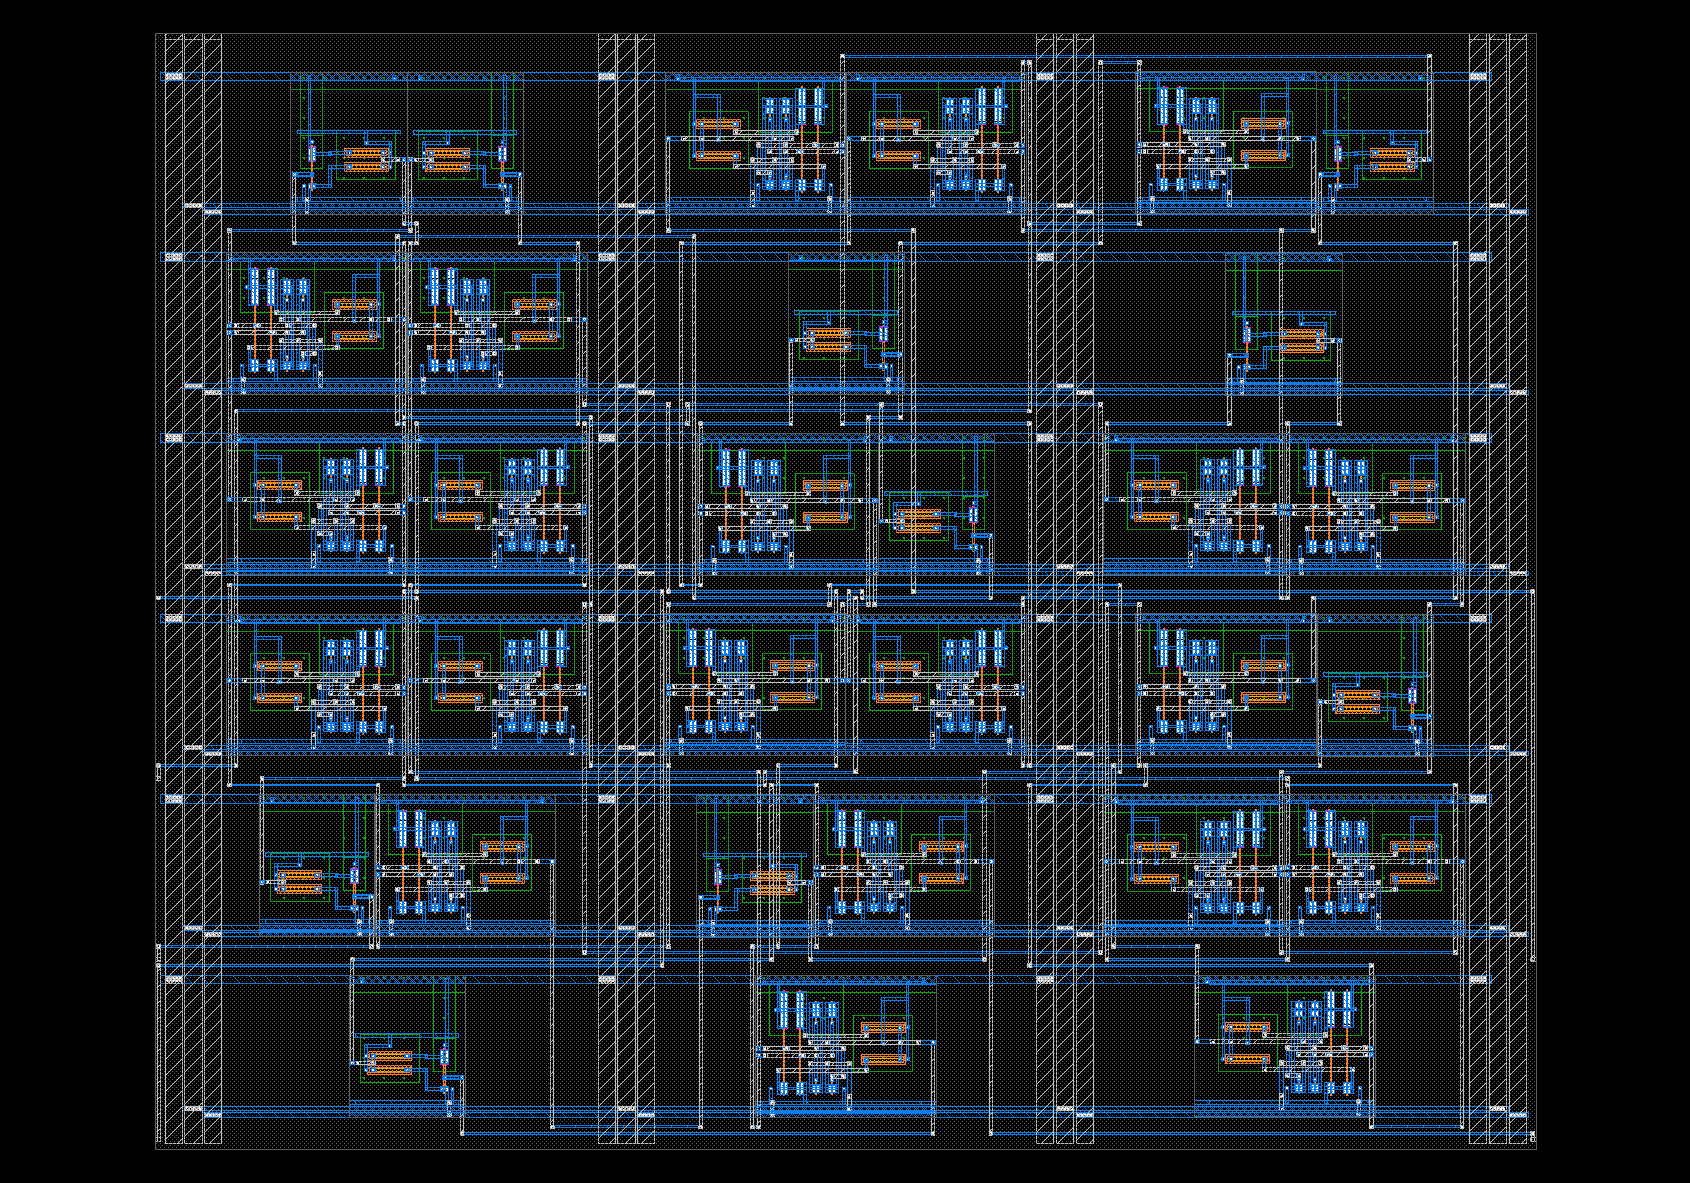

Net,Wire capacitance (fF)
_n1,198.2
_n20,193.3
x0,192.3
x3,191.5
x2,175.9
_n4,160.2
y[0],156.4
_n18,134.1
Total over 35 nets,3047


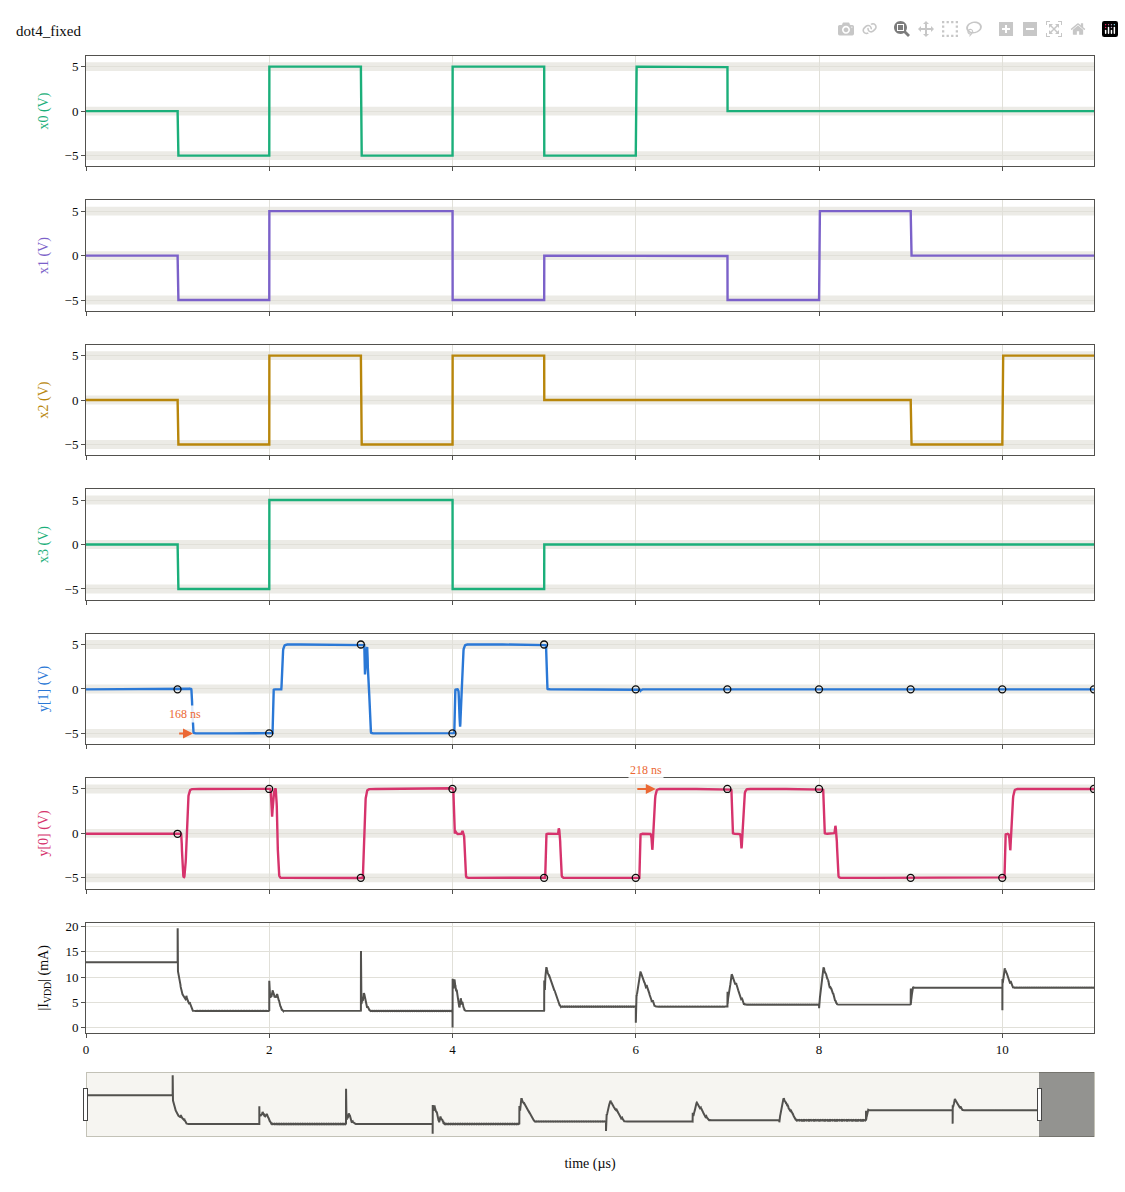

Item,Result
Circuit,dot4_fixed
Cells,31
Macro size (µm),1284 × 1038
DRC violations,0
LVS,Matched
SPICE input states,11 / 81 (sampled states)
Output level and settling,PASS
Max. output error (V),0.0418
y[1] max. settling time (ns),167.9
y[0] max. settling time (ns),218.0


In [31]:
# 6-5 Run the full flow on the edited HDL
need("reuse_source", why="The HDL to run is defined in 6-4.")
from reuse import run
reuse_result = run(reuse_source, output_dir=BUILD/"reuse", step_s=5e-9,
                   exhaustive_limit=27, sample_size=11)

### 6.5 Shuttle Top-Level Layout

To be manufactured in a real fab, the ternary core needs I/O pads around the chip, which means combining it with the MPW (Multi-Project Wafer) stock frame and its electrostatic discharge (ESD) protection devices.

This section builds a top-level layout that connects the dot-product circuit routed in chapter 4 to the stock OpenSUSI TR-1um MPW frame, and verifies it with DRC, LVS and the organizer's precheck.

The key issue is matching the ESD protection to the ternary supply voltages. The ESD devices of the stock pads conduct when a pad's voltage leaves the range of the ESD supplies (VDD and VSS). Ternary signals, on the other hand, span −5 V to +5 V, 10 V in total.

TritFlow therefore ties the frame's ESD VSS to the circuit's VSS (−5 V) and supplies the ESD VDD with +5 V from a separate terminal. The −5 V to +5 V ternary signals then stay within the range of the ESD supplies, and the stock pads can be used unchanged. This is the same connection as on the chip taped out in 2026, OpenSUSI-TR10.

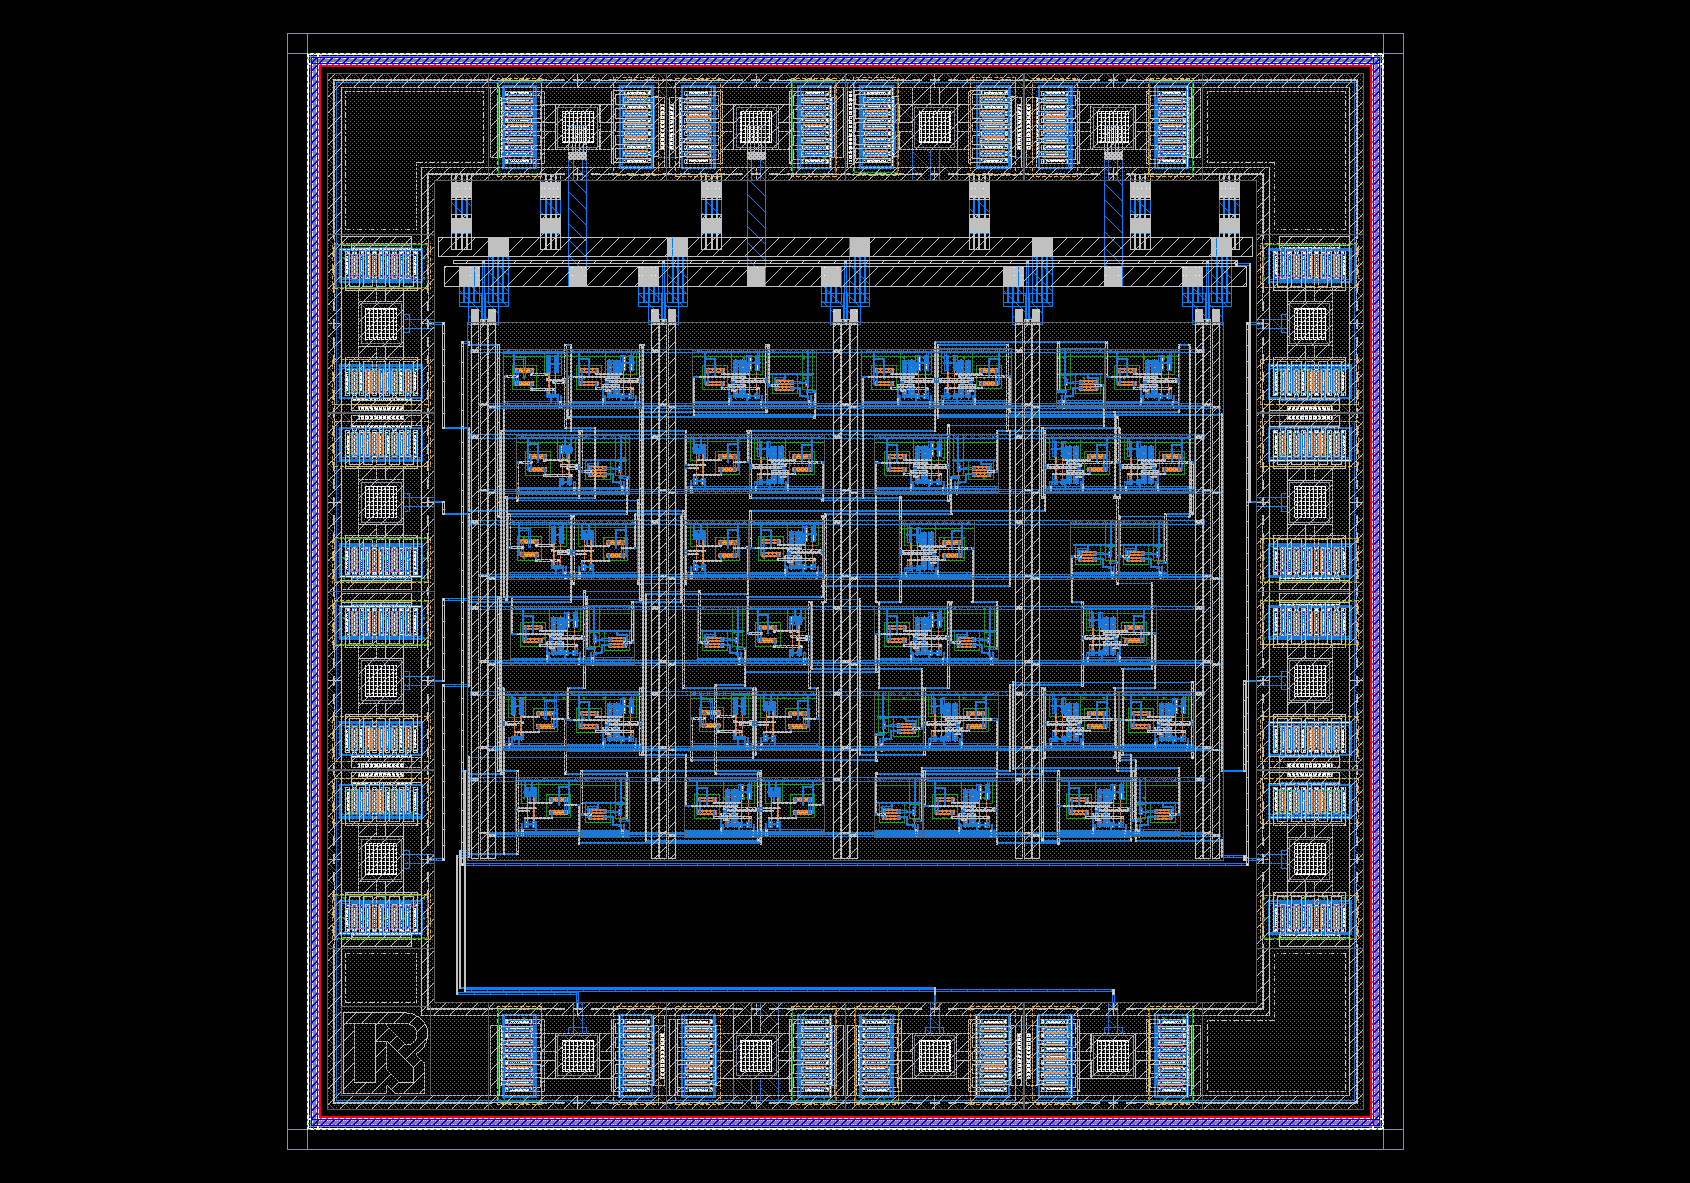

In [32]:
# 6-6 Dot-product circuit with MPW frame and pads
need("dot4_layout", why="The dot4 placed in the frame is routed in 4-1.")
import subprocess
from reuse import chip_view
# The organizer's MPW precheck template, pinned to one commit.
mpw_template = BUILD/"TR-1um_MPW_Sanken"
if not (mpw_template/"scripts/pre_check.py").is_file():
    subprocess.run(["git", "clone", "-q", "https://github.com/munetomo-maruyama/TR-1um_MPW_Sanken.git",
                    str(mpw_template)], check=True)
    subprocess.run(["git", "-C", str(mpw_template), "checkout", "-q",
                    "b3dab389ddaac1056c93bf5704230c6d2f52d5b2"], check=True)
# The precheck runs in a child Python; give it the same KLayout module as this kernel.
import os, pya
os.environ["PYTHONPATH"] = os.pathsep.join(filter(None, [str(Path(pya.__file__).resolve().parents[1]),
                                                         os.environ.get("PYTHONPATH")]))
with step("Place in the MPW frame and verify") as s:
    dot4_chip = dot4_layout.result.to_chip(frame="OSS_FRAME", pdk_root=dot4_layout.settings.pdk,
                                           klayout_binary=dot4_layout.settings.klayout,
                                           output_dir=BUILD/"dot4_chip", mpw_template=mpw_template,
                                           force_signoff=True)
    s.done(f"2500 × 2500 µm · {len(dot4_chip.data['pad_map'])} pads · "
           + ("all checks pass" if dot4_chip.report["clean"] else "some checks fail"))
dot4_chip_report = chip_view(dot4_chip, dot4)

### 6.6 Conclusion

This notebook demonstrated TritFlow, an automated design flow for ternary integrated circuits, on OpenSUSI TR-1um, an open-source PDK released by a commercial semiconductor fab in Japan.

- **A pipeline from a dedicated ternary HDL to GDS**: from a TritVerilog description, the flow runs logic synthesis with simplification by ternary identities, two-metal place and route, GDS output, DRC/LVS with the PDK's official decks, wire-capacitance estimation and post-layout simulation in one pass.
- **A ternary timing model and STA**: delay is defined from the six state transitions and the settling time, and a ternary static timing analysis that estimates delay without SPICE was built and compared with post-layout SPICE.
- **Validation by measurement**: the standard cells keep the circuits and device sizes of the taped-out design, so they can be compared directly with measurements of the chips arriving in January 2027. Because the flow also generates a full-chip layout for the MPW shuttle automatically, a circuit designed with TritFlow can go to a shuttle as is, be fabricated and be checked by measurement.

TritFlow is a first step toward learning balanced-ternary logic circuits, which may find use in ternary computation such as BitNet. All source code, the cell library and the design flow are released under Apache-2.0, giving researchers and students interested in ternary circuits a starting point for their own designs. We hope that this work, which closes the loop from design to fabrication and measurement on TR-1um and the OpenSUSI shuttles, Japan's open-source semiconductor infrastructure, will help open-source chip design grow in Japan.

## 7. Playground

This chapter is a playground where you can design your own ternary circuits and run them through the whole TritFlow flow.

Edit the TritVerilog source in the code cell below and run it: logic synthesis, place and route, GDS generation, DRC/LVS, wire-capacitance estimation and post-layout simulation all run automatically, and the schematic, layout and waveforms are displayed.

The cell starts with a two-trit adder with carries (`add2`). Try circuits such as the following.

- **Selectors**: `op == 1't1 ? a : b` or `case` statements
- **A ternary ALU**: addition `+`, subtraction `-`, AND `&`, OR `|` and negation `~` combined
- **Your own ternary circuits**: cells such as NANY placed directly
- **Dot products**: other term counts or widths

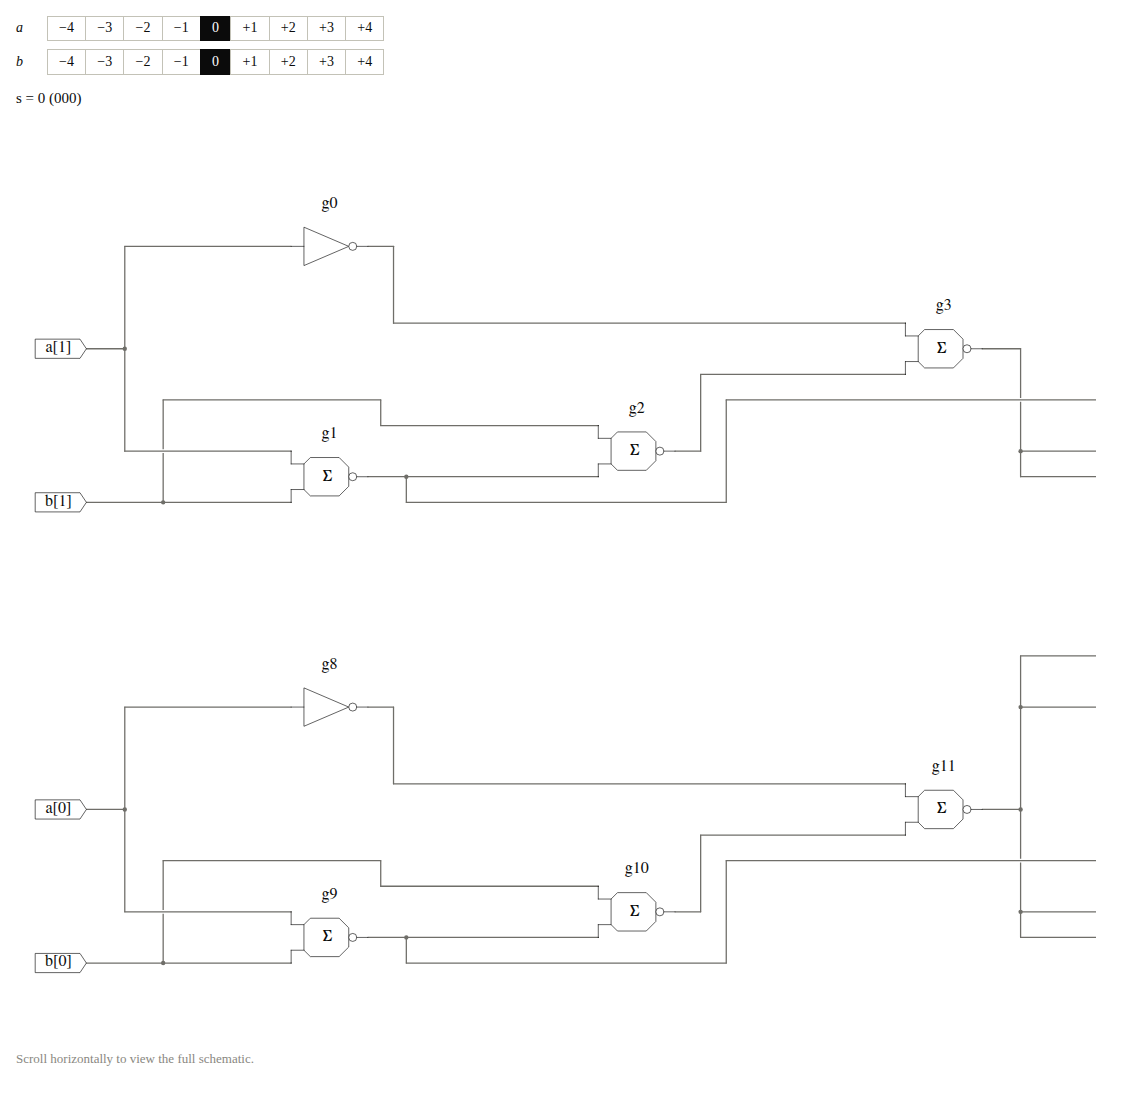

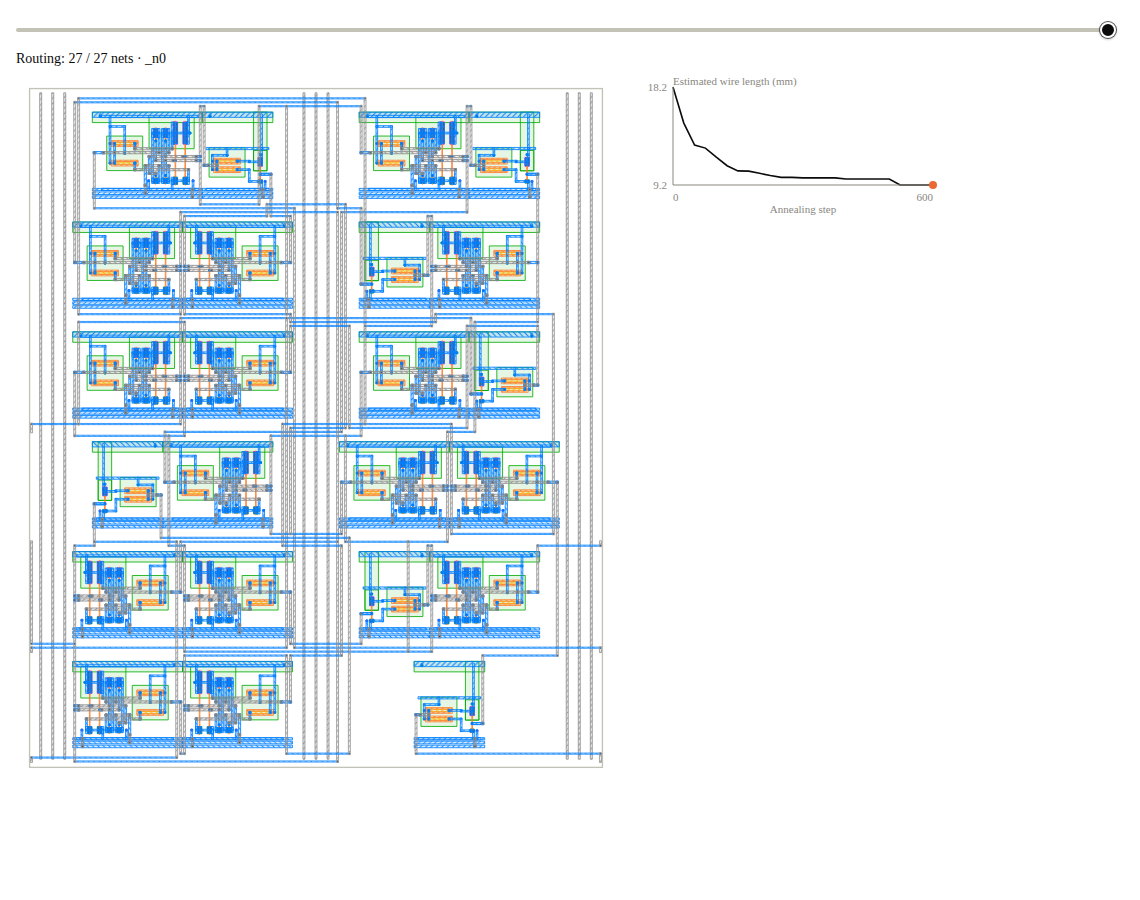

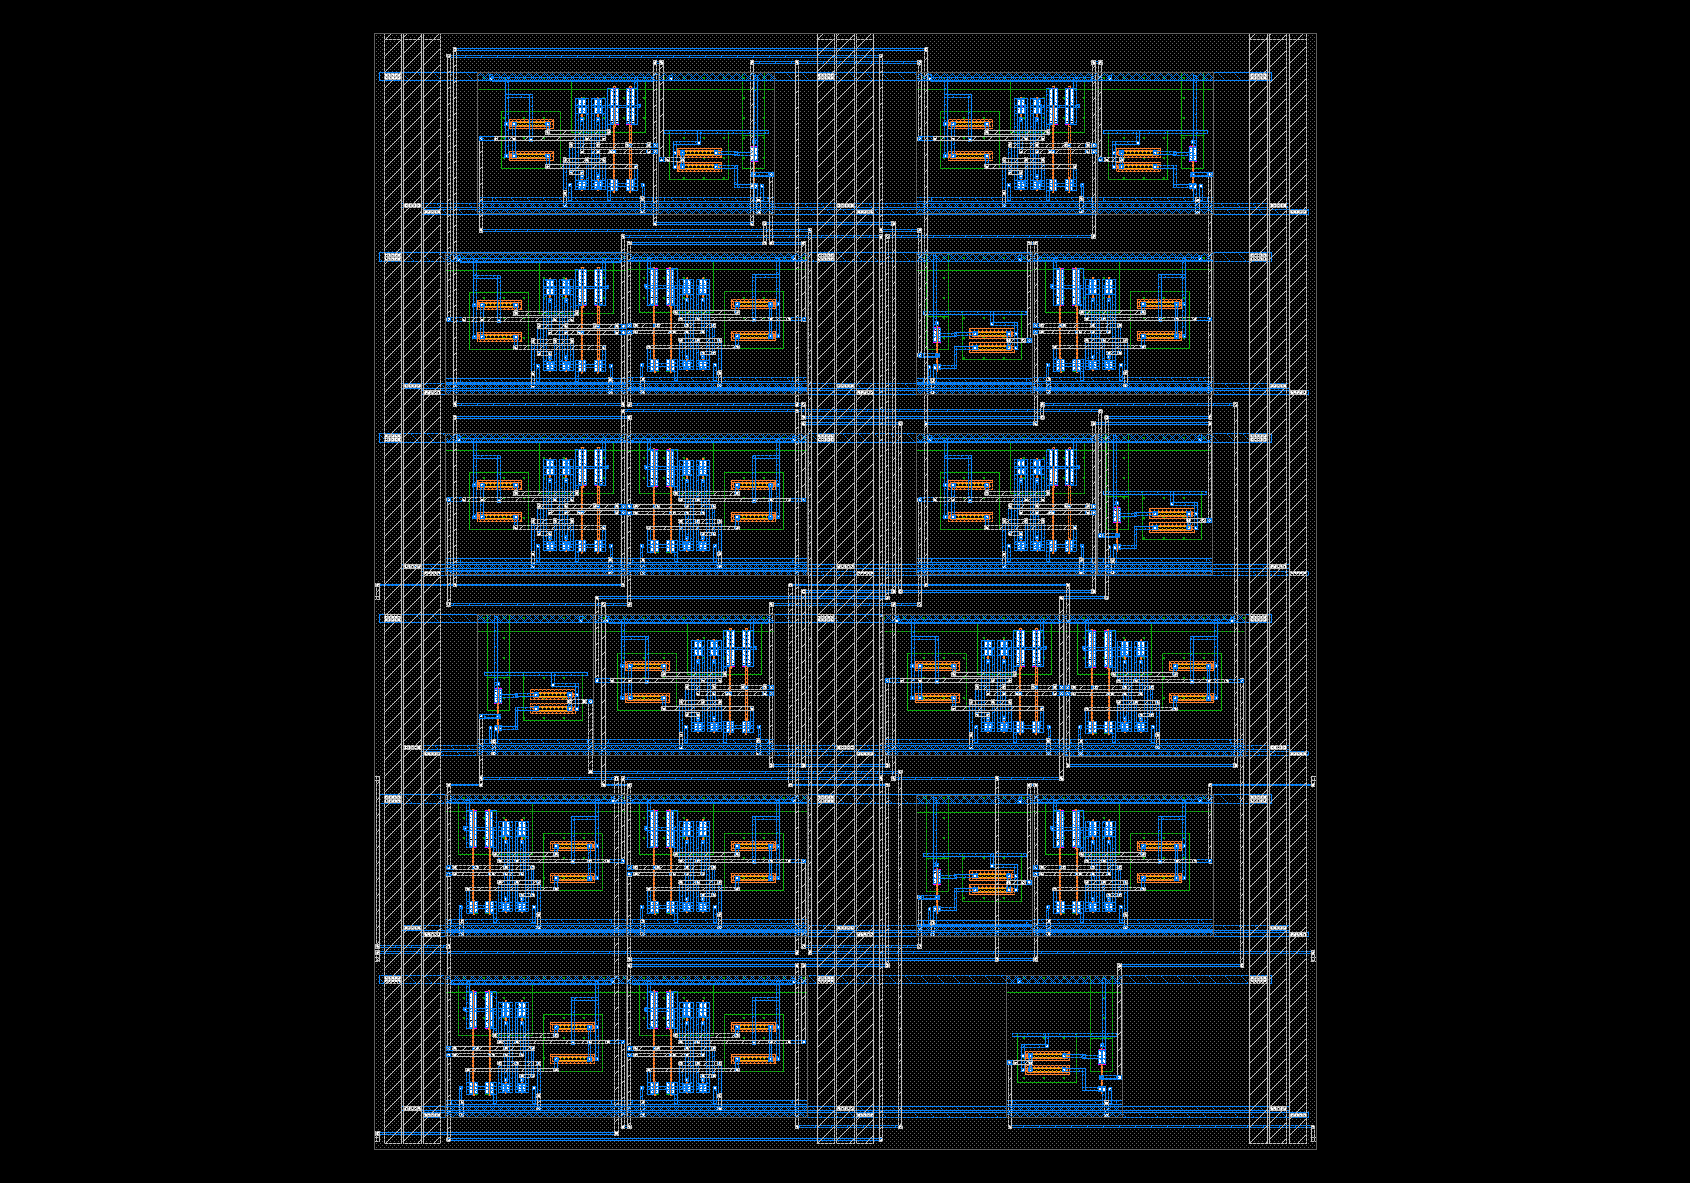

Net,Wire capacitance (fF)
_n3,264.9
_n14,213.0
_n1,196.0
a[0],156.5
s[1],153.3
_n11,147.1
_n12,122.2
_n0,118.5
Total over 27 nets,2232


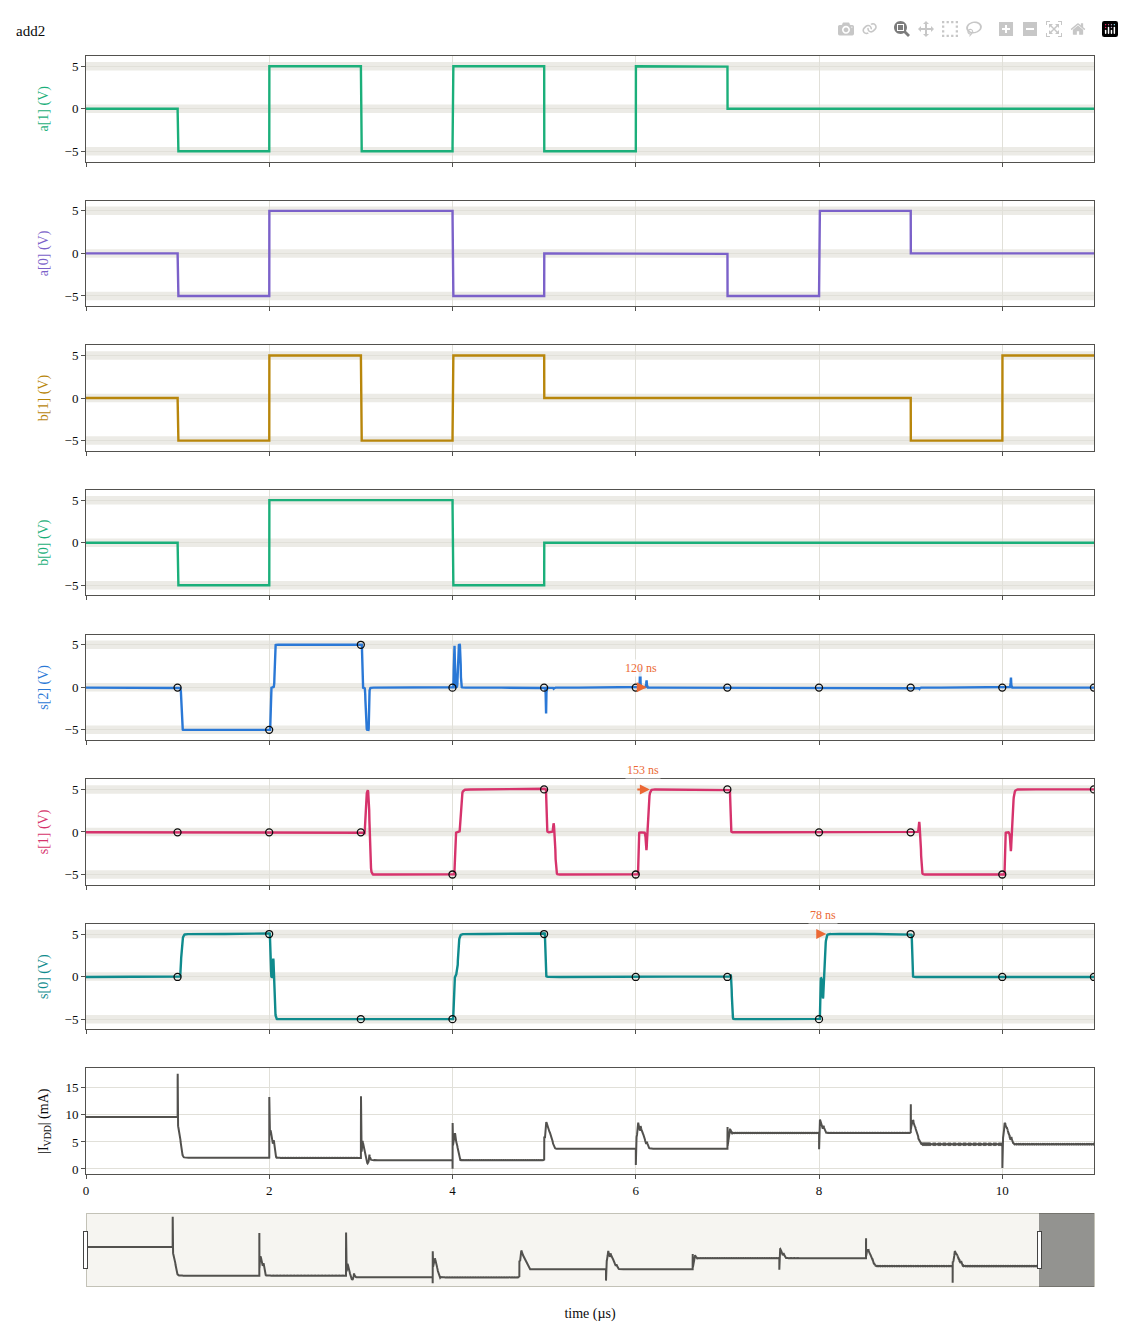

Item,Result
Circuit,add2
Cells,23
Macro size (µm),876 × 1038
DRC violations,0
LVS,Matched
SPICE input states,11 / 81 (sampled states)
Output level and settling,PASS
Max. output error (V),0.0433
s[2] max. settling time (ns),119.6
s[1] max. settling time (ns),153.1


In [33]:
# 7-1 Playground
playground_source = """
module add2(input trit [1:0] a, b, output trit [2:0] s);
  assign s = a + b;
endmodule
"""
from reuse import run
playground = run(playground_source, output_dir=BUILD/"playground", step_s=5e-9,
                 exhaustive_limit=27, sample_size=11)

## References

1. Shuming Ma et al., “The Era of 1-bit LLMs: All Large Language Models are in 1.58 Bits,” arXiv:2402.17764, 2024. [doi:10.48550/arXiv.2402.17764](https://doi.org/10.48550/arXiv.2402.17764).
2. Sheng Lin, Yong-Bin Kim, and Fabrizio Lombardi, “CNTFET-Based Design of Ternary Logic Gates and Arithmetic Circuits,” *IEEE Transactions on Nanotechnology*, 10(2), pp. 217–225, 2011. [doi:10.1109/TNANO.2009.2036845](https://doi.org/10.1109/TNANO.2009.2036845).
3. Xiao-Yuan Wang et al., “High-Density Memristor-CMOS Ternary Logic Family,” *IEEE Transactions on Circuits and Systems I: Regular Papers*, 68(1), pp. 264–274, 2021. [doi:10.1109/TCSI.2020.3027693](https://doi.org/10.1109/TCSI.2020.3027693).
4. Jae Won Jeong et al., “Tunnelling-based ternary metal–oxide–semiconductor technology,” *Nature Electronics*, 2(7), pp. 307–312, 2019. [doi:10.1038/s41928-019-0272-8](https://doi.org/10.1038/s41928-019-0272-8).
5. Hanmok Park, Seonghoon Kim, Sunmean Kim, and Taigon Song, “An RTL-Based General Synthesis Methodology for Device-Independent Ternary Logic Circuits,” *IEEE Access*, 13, pp. 163648–163660, 2025. [doi:10.1109/ACCESS.2025.3597293](https://doi.org/10.1109/ACCESS.2025.3597293).
6. Steven Bos and contributors, *MixedRadixCircuitSynthesis (MRCS)*, source snapshot `0865cee`, 2023. [Repository](https://github.com/aiunderstand/MixedRadixCircuitSynthesis/tree/0865cee1f49fe9a803b4910b570f4e96e514c61b).
7. Mohnish Pai, “Ankhdjet: An Open-Source Compiler for Mask-Programmed Ternary Compute-in-ROM on an Open PDK,” arXiv:2608.26206, 2026. [doi:10.48550/arXiv.2608.26206](https://doi.org/10.48550/arXiv.2608.26206).
8. Jerzy Słupecki, “Kryterium pełności wielowartościowych systemów logiki zdań,” *Comptes Rendus des Séances de la Société des Sciences et des Lettres de Varsovie, Classe III*, 32, pp. 102–109, 1939. [Original text](https://rcin.org.pl/Content/50652/PDF/WA35_4821_cz167-r1939-t32_Spraw-TNW-wIII-art1.pdf#page=110).
9. Jean W. Butler, “On complete and independent sets of operations in finite algebras,” *Pacific Journal of Mathematics*, 10(4), pp. 1169–1179, 1960. [Full text](https://msp.org/pjm/1960/10-4/pjm-v10-n4-p10-s.pdf).
10. Stephen Cole Kleene, *Introduction to Metamathematics*, North-Holland / P. Noordhoff, 1952, §64. [Bibliographic record](https://cir.nii.ac.jp/crid/1971712334708500134).
11. Francesco Paoli and Gavin St. John, “Editorial Introduction,” *Studia Logica*, 112, pp. 1201–1214, 2024. [doi:10.1007/s11225-024-10147-9](https://doi.org/10.1007/s11225-024-10147-9).
12. OpenSUSI, Tokai Rika, and contributors, *TR-1um Open Source PDK project*, commit `5d963db`, 2026. [PDK used](https://github.com/OpenSUSI/TR-1um/tree/5d963db9d44e192d37a0489c208bfccf2e2f690c).
13. Robin Lu and contributors, *TR-1um: an experiment to port TR-1um and OpenSUSI MPW template to LibreLane + ALIGN*, source snapshot `b14b3f5`, 2026. [Repository](https://github.com/luyanaa/TR-1um/tree/b14b3f5cca671fd86804e3cca434a0a728c73642).
14. Einosuke Okazaki, *平衡3値論理回路 — OpenSUSI TR-1um (opensusi-tr10-balanced-ternary-logic)*, source snapshot `8a60b97`, 2026. [Source circuits and submission](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic/tree/8a60b97868cad008ff21fefca5da13dcd06063f8).
15. 一般社団法人OpenSUSI, “OpenSUSI-MPW第1回募集を完了 — 企業・大学・高専・高校・個人から49枠の申し込み,” 2026年10月16日. [Announcement](https://prtimes.jp/main/html/rd/p/000000014.000182004.html).
16. Matthias Köfferlein and the KLayout contributors, *KLayout Layout Viewer and Editor*, version 0.30.6, 2026. [Release](https://github.com/KLayout/klayout/releases/tag/v0.30.6).
17. Holger Vogt, Giles Atkinson, and Paolo Nenzi, *Ngspice User's Manual*, version 42, 2023. [Manual](https://sourceforge.net/projects/ngspice/files/ng-spice-rework/old-releases/42/ngspice-42-manual.pdf/download).
18. ISHI会, “2025年12月イベント「東海理化シャトルのオープンPDK解説会」の参加者募集,” 2025年10月30日. [Announcement](https://ishi-kai.org/information/seminar/2025/10/30/DecEvent_1213.html).
19. Zane Hambly, *Takahe*, source snapshot `e7123ea`, 2026. [Binary-encoded SKY130 example](https://github.com/Zaneham/takahe/blob/e7123ea60269922acb283d576678a3aabe51f4f4/designs/setun70_physical.sv).
20. Nikolay P. Brusentsov and José Ramil Alvarez, “Ternary Computers: The Setun and the Setun 70,” in *Perspectives on Soviet and Russian Computing (SoRuCom 2011)*, IFIP AICT 357, Springer, pp. 74–80, 2011. [doi:10.1007/978-3-642-22816-2_10](https://doi.org/10.1007/978-3-642-22816-2_10)

In [34]:
import importlib.metadata as _metadata
import json as _json
import platform as _platform
import subprocess as _subprocess
from IPython.display import display as _display

def _submission_evidence(namespace):
    """Record logic coverage, routed dimensions and nominal analog checks."""
    result = {"schema_version": 1, "designs": {}}
    for name, label in (("net", "first"), ("full_add_rtl", "full_add"),
                        ("mul", "mul"), ("dot4", "dot4")):
        circuit = namespace.get(name)
        if circuit is None:
            continue
        row = {"report": circuit.report(), "equivalence": dict(circuit.equivalence)}
        layout = namespace.get("dot4_layout" if name == "dot4" else "lay") if name in ("net", "dot4") else None
        if layout is not None:
            row["layout"] = dict(layout.stats)
            for key, variable in (("drc", "dot4_drc" if name == "dot4" else "drc"),
                                  ("lvs", "dot4_lvs" if name == "dot4" else "lvs")):
                check = namespace.get(variable)
                if check is not None:
                    row[key] = {k: check[k] for k in
                                ("clean", "violations", "matched", "strict_ports", "scope")
                                if k in check}
            post = namespace.get("dot4_post" if name == "dot4" else "post")
            if post is not None:
                row["measurements"] = post["measurements"]
                row["stimulus"] = post["stimulus"]
        if name == "dot4" and "dot4_timing" in namespace:
            row["sta_arrival_s"] = dict(namespace["dot4_timing"].arrival)
        result["designs"][label] = row
    # An optional future chapter can provide an explicit summary. Its rendered
    # tables are independently retained by the builder even without this key.
    if "submission_results" in namespace:
        result["evaluation"] = namespace["submission_results"]
    result["runtime"] = {"python": _platform.python_version(), "packages": {}}
    for package in ("numpy", "scipy", "plotly", "klayout", "lark", "matplotlib"):
        result["runtime"]["packages"][package] = _metadata.version(package)
    result["runtime"]["tools"] = namespace.get("tools", {})
    from tritflow import PDK_ROOT as _pdk_root
    from tritflow.sim.provenance import pdk_provenance as _pdk_provenance
    result["pdk"] = _pdk_provenance(_pdk_root)
    result["source_ref"] = namespace.get("SOURCE_REF")
    result["runtime_commit_at_end"] = _subprocess.check_output(
        ["git", "-C", str(namespace["ROOT"]), "rev-parse", "HEAD"], text=True).strip()
    result["runtime_commit"] = namespace.get("_submission_runtime_commit_at_start", result["runtime_commit_at_end"])
    result["tracked_working_changes_at_execution"] = _subprocess.check_output(
        ["git", "-C", str(namespace["ROOT"]), "diff", "--name-only", "HEAD"], text=True).splitlines()
    result["untracked_runtime_sources_at_execution"] = _subprocess.check_output(
        ["git", "-C", str(namespace["ROOT"]), "ls-files", "--others", "--exclude-standard",
         "tritflow", "notebook", "cells", "examples", "results"], text=True).splitlines()
    # Reject NaN/Infinity: a failed measurement must never become a result.
    return _json.loads(_json.dumps(result, allow_nan=False, default=str))

_display({"application/json": _submission_evidence(globals()),
          "text/plain": "Submission evidence: executed logic, layout, verification and timing results."}, raw=True)

Submission evidence: executed logic, layout, verification and timing results.

## Submission references and reuse

- [TritFlow source](https://github.com/PenguinEino/tritflow).
- [OpenSUSI TR-1um PDK](https://github.com/OpenSUSI/TR-1um).
- [Author's taped-out balanced-ternary cells and 1-trit multiply-add](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic).
- [KLayout](https://www.klayout.de/), [ngspice](https://ngspice.sourceforge.io/), [Plotly](https://plotly.com/python/), [Lark](https://github.com/lark-parser/lark).

Earlier Code-a-Chip notebooks were consulted for presentation and packaging; no notebook cells or code were copied from those submissions. The complete notebook bibliography, when present, remains in the original chapter cells.

Saved images are actual captured initial views. Re-execute the unchanged source cells for controls and animation. Pinned Markdown images are embedded for offline reading. Machine paths in outputs are normalized; numerical data is unchanged.

<details><summary>Capture and source provenance</summary>

Immutable source commit `e533a3cfbd39b07243faaa417b9ceb359da0c1f0` matches the packaged notebook, allowing its commit-stamp line (local git-object check).

This package records local execution of v3; historical v1 Colab evidence is not promoted to v3.

Pinned bootstrap commit: `9048276bcbd4c84dd27d7df9f3cf44493283f2fe`. Observed execution commit: `9048276bcbd4c84dd27d7df9f3cf44493283f2fe`.

```json
{
  "python": "3.12.3",
  "packages": {
    "numpy": "2.4.3",
    "scipy": "1.17.1",
    "plotly": "7.1.0",
    "klayout": "0.30.6",
    "lark": "1.3.1",
    "matplotlib": "3.10.8"
  },
  "tools": {
    "KLayout": "KLayout 0.30.9",
    "ngspice": "******\n** ngspice-42 : Circuit level simulation program\n** Compiled with KLU Direct Linear Solver\n** The U. C. Berkeley CAD Group\n** Copyright 1985-1994, Regents of the University of California.\n** Copyright 2001-2023, The ngspice team.\n** Please get your ngspice manual from https://ngspice.sourceforge.io/docs.html\n** Please file your bug-reports at http://ngspice.sourceforge.net/bugrep.html\n** Creation Date: Sun Mar 31 20:15:14 UTC 2024\n******"
  }
}
```

</details>